## Abstract

Transformers trained on planetary orbits can predict planet movement with high fidelity under multiple possible 'world models'. Here, we apply Equivalent Linear Mapping to precisely characterize how a transformer builds its predictions from two past planetary positions.

:::{.callout-note title="AI usage disclosure" collapse="true"}
We used Claude (Opus 5.5) to help write code, clean up code, comment our code, and review our code. We also used Claude to suggest wording ideas and write text, and Claude suggested the matrix decomposition we used. We used Grammarly Enterprise to copy-edit draft text to match Arcadia's style.
:::

## Purpose

@liu2026kepler investigated the world models learned by transformers trained to predict planetary motion. Using linear probes, they found evidence that their transformers learned Keplerian or Newtonian world models depending on inductive biases such as context length. However, while linear probes can reveal what's encoded in a model, they don't necessarily reveal how a model computed its prediction. Here, we open the black box by applying Equivalent Linear Mapping (ELM) to rewrite the trained models as an exact per-input linear map. This lets us directly understand how each transformer arrives at its prediction, revealing the underlying learned world model.

## Introduction
The strong performance of foundation models across scientific domains has spurred interest in their internal workings, particularly in the “world models” they are said to learn. Loosely, world models are defined as the internal representation a network builds of the process that generated its training data, which shapes the implicit rules it learns to use to make predictions. Methods that can reliably reveal these learned representations could therefore serve as useful tools for surfacing structure in training data that no explicit supervision targeted.

A popular approach to elucidating world models uses probes (both linear and nonlinear) [@alain2016probes; @conneau2018cram] to test whether a variable of interest can be decoded from a learned representation. This has been applied extensively to argue that world models emerge in sequence predictors, from board game state in models trained on Othello moves [@li2023othello], to linear representations of space and time in large language models [@gurnee2024space]. However, this inference can be fragile. The success of a probe is contingent on the chosen target and how it is parameterized [see @nanda2023linear], and, more fundamentally, a probe reports what is encoded, not what is computed with [@ravichander2021probing]. 

A complementary approach tests whether a network’s inductive bias aligns with a world model by fine-tuning it on synthetic tasks derived from it. Few-shot extrapolations can then be assessed to see if they’re organized by the world model’s state [@vafa2025foundation]. This method was recently applied to transformers trained on simulated planetary orbits. Intriguingly, it revealed that models can achieve near-perfect trajectory prediction without appearing to learn Newtonian states, suggesting that they learn task-specific heuristics rather than underlying physical laws. @liu2026kepler followed up on this work, asking whether or not it might be possible to steer the transformers toward learning the true world model by building inductive biases into model architecture and training. They found that models trained with long-context windows appeared to leverage Keplerian ellipse fitting, whereas models with shorter-context windows were constrained to using Newtonian force. However, decoding force or orbital parameters from activations does not necessarily show that the network uses them. Do these transformers compute with the world model their probes recover?

Here, we tackle the question of world models with a complementary approach, equivalent linear mapping (ELM), which targets what other methods are blind to: the computation itself. Mechanistic interpretability has shown that transformer computations can, in principle, be read directly from model weights and activations [@elhage2021framework], but this work has largely focused on specific circuit-level phenomena rather than inferring world models. ELM makes this exercise tractable by rewriting each trained network as an exact per-input linear map, which allows us to read the end-to-end computation mechanism directly from the models’ Jacobians. 
Using ELM, we build on the work of @liu2026kepler using transformers trained on simulated planetary orbits as a toy system of world model emergence and inference. Taking the Verlet integrator as a reference computation compatible with a Newtonian world model, we ask how closely each network’s recovered computation map matches it. We find that despite carrying linearly decodable Newtonian force variables, the short-context transformer of Liu et al. computes a circular-rotation heuristic, a mechanism that works sufficiently well for the one-step prediction training task but does not rely on Newtonian force. We trace this to the input noise the authors inject during training to stabilize model rollouts. Retraining the short-context model without noise yields a network whose input-level operations closely match Verlet integration, consistent with a genuine Newtonian world model. We further show that while linear probes can recover Newtonian force components in both models, they do so by leveraging low-variance dimensions in model activation space, which themselves do not seem to be necessary for the emergence of Newtonian force in model predictions. Our analysis represents a worked example of identifying a network’s internal computation without internal probing, and of adjudicating among candidate world models against a known ground truth when one is available.



## The setup

The training data is 2D planetary orbits under an inverse-square force, $\ddot{\mathbf r} = -\,GM\,\mathbf r/|\mathbf r|^{3}$ (units with $GM=1$). The transformer reads a sequence of past positions $\mathbf r_0, \mathbf r_1, \dots$ and predicts the next one, $\hat{\mathbf r}_{t+1}$. Its context length is the number of past positions it can attend to. Two alternative models can, in principle, be used to fit the training data:

- a **Newtonian** model: estimate the local gravitational force from the last one or two positions and integrate $F = ma$. In this context, this is the “true” world model which captures the generative process behind the data.

- a **Keplerian** model: fit the global ellipse through the observed points and continue along it. While ellipse fitting can work very well for predicting planetary position, it fails to capture the true world model. 


**The data.** We reuse Liu et al.'s data-generation procedure. Each trajectory is a bound elliptical orbit obtained by numerically integrating $\ddot{\mathbf r} = -\,GM\,\mathbf r/|\mathbf r|^{3}$ ($GM = 1$) with SciPy's `solve_ivp` at relative and absolute tolerances of $10^{-8}$. Orbits are initialized at perihelion with parameters drawn uniformly: eccentricity $e \in [0, 0.8]$, semi-major axis $a \in [0.5, 2.0]$, and orientation $\theta \in [0, 2\pi]$, with the initial state rotated by $\theta$. Each trajectory is sampled at 100 equally spaced points, giving sequences of shape $(100, 2)$. The nominal step is $\Delta t = 0.2$, but the generator lays the 100 samples out over $[0, 20]$ with `linspace`, so the true spacing is $20/99 \approx 0.202$, 1% wider. We inherit this from Liu et al.'s generator and use the true spacing wherever we compare the model against a physical formula. Note the eccentricity distribution is broad (uniform up to $e = 0.8$, mean $0.4$): the typical training orbit is appreciably non-circular, which will matter when we characterize what the short-context model actually learns.

**What we train.** We retrain Liu et al.'s model, a small GPT-2-style transformer (a modified nanoGPT), from scratch at the two context lengths that bracket their result: 2 and 100. We train both models using Liu et al.'s noisy-context training (input positions perturbed by Gaussian noise $\sigma = 0.1$) that stabilizes autoregressive prediction. Additionally, we train a noiseless context length 2 model ($\sigma = 0$). Our one departure from their setup is that we disable every bias term as the ELM analysis below needs the network to be a homogeneous linear map at each operating point.

With the models in hand, our first two analyses set up the tools the rest of the pub relies on: (1) the ELM decomposition is exact, so its per-input attributions are trustworthy; and (2) linear probing reproduces the world model phase transition reported by Liu et al. on our model checkpoints.


::: {.callout-note collapse="true" title="Model architecture and training (details)"}

**Architecture.** Each model is a small decoder-only GPT (a bias-free modification of nanoGPT), identical at the two context lengths except for the block size:

- **Depth/width:** 2 pre-norm transformer blocks, 1 attention head, embedding dimension $d_{\text{model}} = 32$ (MLP hidden width $4d = 128$, SiLU activation), for $\approx\!25\text{k}$ parameters total.

- **Continuous I/O (no tokenizer):** each 2D position $\mathbf r_t \in \mathbb{R}^2$ is linearly projected into the 32-dim residual stream, a learned sequence-position embedding $\mathrm{wpe}[t]$ is added, and a final linear head maps the stream back to $\mathbb{R}^2$ to predict the next position. We nonetheless refer to each input position as a token, as is standard for continuous-input transformers.

- **Context length (block size):** 2 or 100.

- **No bias terms:** attention heads, MLP, LayerNorm, and both I/O projections (see ELM section for explanation) are trained with no biases. Standard LayerNorm (scale only), dropout $0$, and no log-position attention scaling ($\alpha = 0$).

**Training.**

- **Data:** 10,000 trajectories for training and 10,000 held out for test, each 100 points long, chopped into sliding (input-window, next-position) pairs.

- **Objective:** mean-squared error on the next-position prediction, one step ahead, with no autoregressive rollout in the loss. At context length 100, every input position is supervised, each against the position that follows it; at context length 2 each training window carries a single target, so only the prediction ($\hat{\mathbf r}_{t+1}$) made from the full window $(\mathbf r_{t-1}, \mathbf r_t)$ is supervised.

- **Optimizer:** AdamW, learning rate $10^{-3}$ decayed by $10\times$ at the halfway point, weight decay $0$, batch size $128 \times 100/\text{block size}$ (6,400 at context length 2, 128 at context length 100), $20{,}000$ steps, seed $1$.

- **Noisy-context augmentation:** input positions are perturbed with Gaussian noise $\mathcal{N}(0, \sigma^2)$ during training. We train a noisy short-context model ($\sigma = 0.1$, following Liu et al.) and a noiseless one ($\sigma = 0$) at block size 2, plus a noisy long-context model ($\sigma = 0.1$, block size 100).

The architecture, weight initialization, and data-generation procedure follow @liu2026kepler; disabling the bias terms is our only architectural change. Full definitions are in src/analysis/model.py and src/analysis/training.py.

:::


In [1]:
#| code-fold: true
#| output: false
import io
import os
import contextlib

import numpy as np
import torch
import matplotlib.pyplot as plt
import arcadia_pycolor as apc

from analysis.model import load_from_checkpoint
from analysis.elm import (apply_figure_style, style_panel,
                          ARC_VIBE, ARC_CORAL, ARC_DIAG,
                          C_TOKEN_PREV, C_TOKEN_RECENT,
                          C_MODEL_NOISY, C_MODEL_NOISELESS,
                          C_CTX_2, C_CTX_100,
                          C_TRUE, C_IDEAL, C_MODEL)

apply_figure_style()   # Arcadia matplotlib style; must precede the first figure

torch.set_default_dtype(torch.float64)   # ELM reconstruction is exact only at float64

CHECKPOINT_DIR = './checkpoints/kepler_cv_blocksize_elm'
DATA_DIR       = 'data_cv'
NUM_TRAJ, NOISE_SCALE, SEED = 10000, 0.1, 0

# Sample spacing of the trajectories. NOT the nominal 0.2: the upstream generator
# samples with t_eval = linspace(0, num_points*dt, num_points), so 100 points over
# [0, 20] land 20/99 apart. Used wherever we compare the model to a physical formula.
DT = 20 / 99
CKPT_BS2   = f'{CHECKPOINT_DIR}/model_block_size_2_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'
CKPT_BS100 = f'{CHECKPOINT_DIR}/model_block_size_100_num_trajectories_{NUM_TRAJ}_noise_scale_{NOISE_SCALE}.pt'

with contextlib.redirect_stdout(io.StringIO()):
    model_bs2,   _ = load_from_checkpoint(CKPT_BS2,   device='cpu'); model_bs2.eval()
    model_bs100, _ = load_from_checkpoint(CKPT_BS100, device='cpu'); model_bs100.eval()


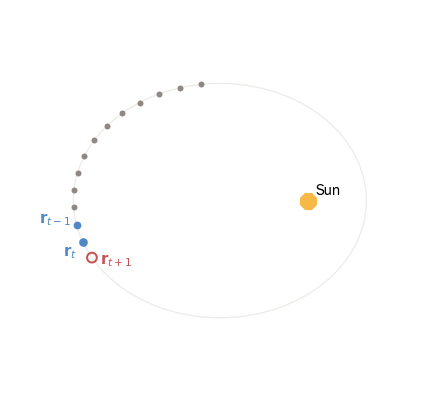

In [2]:
#| label: fig-setup
#| fig-cap: "The task: a transformer sees past positions along an orbit and must predict the next planetary position ($r_{t+1}$). A short-context model is only allowed to attend to the last two positions ($r_{t-1}, r_t$) to make that prediction."
#| fig-alt: "Schematic of an elliptical orbit around a central star. Earlier positions are marked faintly along the ellipse, the two most recent positions are highlighted, and the position to be predicted is outlined just ahead of them."
#| code-fold: true

_a, _e = 1.35, 0.6; _b = _a*np.sqrt(1-_e**2); _c = _a*_e
_E = np.linspace(0, 2*np.pi, 300); _ex, _ey = _a*np.cos(_E), _b*np.sin(_E); _sun = np.array([_c, 0.0])
_Es  = np.linspace(1.7, 3.5, 13)
_pts = np.stack([_a*np.cos(_Es), _b*np.sin(_Es)], 1)
_rp, _rt = _pts[-2], _pts[-1]
_En = 2*_Es[-1] - _Es[-2]; _rn = np.array([_a*np.cos(_En), _b*np.sin(_En)])

PANEL   = apc.mpl.FIGURE_SIZES_IN_INCHES['half_square']
C_ORBIT = str(apc.gray);     C_SUN  = str(apc.canary)
C_PAST  = str(apc.bark);  C_SEEN = apc.aegean
C_NEXT  = str(apc.dragon)


def _orbit_axes():
    """Shared backdrop: the ellipse, the star, and a clean square frame."""
    fig, ax = plt.subplots(figsize=PANEL)
    ax.plot(_ex, _ey, color=C_ORBIT, lw=1.3, zorder=0)
    ax.scatter(*_sun, marker='8', s=340, color=C_SUN, edgecolor=str(apc.crow), zorder=6)
    ax.set_aspect('equal')
    ax.set_xlim(-_a-0.4, _a+0.4); ax.set_ylim(-_b-0.5, _b+0.5)
    ax.set_axis_off()
    return fig, ax


fig, ax = _orbit_axes()
ax.scatter(_pts[:-2, 0], _pts[:-2, 1], color=C_PAST, zorder=3)
ax.scatter(*_rp, s=60, color=C_SEEN, zorder=4)
ax.scatter(*_rt, s=75, color=C_SEEN, edgecolor=str(apc.crow), zorder=4)
ax.scatter(*_rn, s=95, facecolor='none', edgecolor=C_NEXT, lw=2, zorder=5)
ax.annotate(r'$\mathbf{r}_{t-1}$', _rp, textcoords='offset points', xytext=(-38, 2), color=C_SEEN)
ax.annotate(r'$\mathbf{r}_t$', _rt, textcoords='offset points', xytext=(-20, -14), color=C_SEEN)
ax.annotate(r'${\mathbf{r}}_{t+1}$', _rn, textcoords='offset points',
            xytext=(8, -6), color=C_NEXT)
ax.annotate('Sun', _sun, textcoords='offset points', xytext=(8, 6))

plt.show()


## Applying the ELM decomposition

Once we have a trained model, we can apply ELM to assess how it computes its prediction from the past planetary coordinates it receives as input. A transformer is nonlinear, so in general, no single matrix maps its input to its output. However, that nonlinearity is concentrated in a few input-dependent transformations, such as how strongly each vector is normalized, which neurons the gates switch on, and where attention looks. ELM freezes those choices at the values they take for one specific input $x^*$ and detaches them from the gradient [@golden2025elm]. For that input, the network then behaves as an exact linear map, which we can read off as a set of detached Jacobian matrices $J_i(x^*)$ and interpret directly:

$$y^* \;=\; \sum_i J_i(x^*)\, x_i^* \qquad\text{(exact at }x^*\text{).}$$

This reconstruction is degree-1 homogeneous; it contains no additive constant. We therefore train all models with bias terms disabled, which ensures the map is genuinely homogeneous and the reconstruction is exact to float64 precision (~1e-16) rather than approximate.

We freeze three nonlinearities: the LayerNorm scale, the SiLU gate, and the attention weights, after which the input-to-output map is exactly linear-homogeneous at $x^*$. The details of how each is detached are below.

::: {.callout-note collapse="true" title="How the three nonlinearities are detached"}
- **LayerNorm denominator** — the RMS normalization constant $\sigma(x^*)$ is frozen, so the gradient sees only the linear numerator $x / \sigma(x^*)$. The mean-centering $(x - \bar{x})$ is *kept* in the gradient path because it is itself linear (multiplication by $C = I - \mathbf{1}\mathbf{1}^\top/d$).
- **SiLU gate** — $\text{SiLU}(x) = x\cdot\sigma(x)$ is linearized as $x\cdot\sigma(x^*)$, freezing the sigmoid factor so only the linear $x$ carries gradient.
- **Attention weights** — both the query $Q$ and key $K$ are detached before the score computation, freezing the full attention matrix $A(x^*)$; gradient flows only through the value path $V = W_V x$.
:::

**Content vs. positional split.** Here, the output is the predicted position and the input tokens are the previous observed positions, $y^* = \hat{\mathbf r}_{t+1}$ and $x_i = \mathbf r_i$. The transformer architecture used by Liu et al. adds a sequence-position embedding to each token, $h_i = W_{\text{in}}\,\mathbf r_i + \mathrm{wpe}[i]$ (built from the word position embedding (wpe) parameters of nanoGPT), the one constant offset we do not remove from the model. To get around this, we differentiate downstream of that embedding sum, treating $h_i$ as the variable, which is exactly linear after detachment and splits cleanly into a part driven by the input positions (hereafter referred to as *content* terms) and a part driven by the (input-independent[^2]) sequence-position embeddings:

$$\hat{\mathbf r}_{t+1} \;=\; \underbrace{\sum_i J_{h,i}\, W_{\text{in}}\, \mathbf r_i}_{\text{content}}
\;+\; \underbrace{\sum_i J_{h,i}\, \mathrm{wpe}[i]}_{\text{positional}}$$

Write $J_i = J_{h,i}\,W_{\text{in}}$ for the $2\times2$ content blocks (in $(x,y)$ coordinates) and $\mathbf P$ for the positional embedding term sum. The short-context model sees a window of two positions, so the identity we interpret from here on is one $2\times2$ block per input position, plus one sequence-position vector:

$$\hat{\mathbf r}_{t+1} \;=\; \underbrace{J_t\,\mathbf r_t \;+\; J_{t-1}\,\mathbf r_{t-1}}_{\text{content}} \;+\; \underbrace{\mathbf P}_{\text{positional}}$$


**Verification.** @fig-elm-recon plots the model's true forward output against the ELM reconstruction for the last output token, at both context lengths. The points lie on the identity line with relative error $\sim 10^{- 16}$ (machine precision), verifying that the detached Jacobian is an exact stand-in for the model at $x^*$. This result confirms the per-token attributions used in the rest of this pub are trustworthy.

[^2]:The sequence-position embeddings are a learned static vector per sequence slot, invariant with respect to the input coordinates during inference, which is what lets us split them off from the content terms. The positional *contribution* $\mathbf P$ is not input-independent, though, because the detached Jacobians $J_{h,i}$ vary with the operating point.


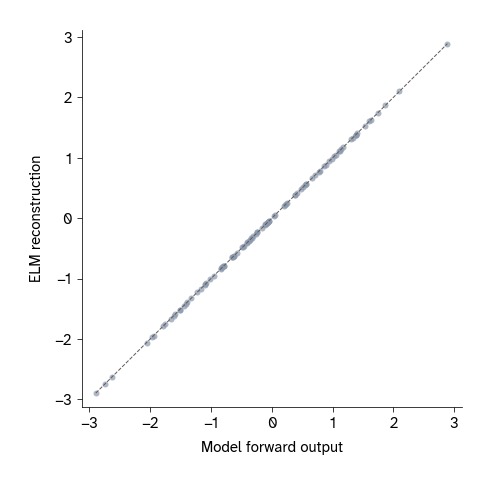

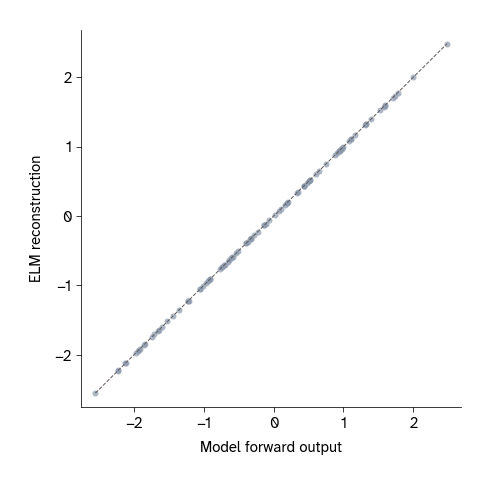

In [3]:
#| label: fig-elm-recon
#| fig-cap: "Equivalent linear mapping (ELM) reconstruction against the model's own forward output for the last output token. One point per window; the dashed line is the identity."
#| fig-subcap:
#|   - "Context length 2."
#|   - "Context length 100."
#| fig-alt:
#|   - "Model output against reconstruction; the points lie on the dashed diagonal with no visible departure from it."
#|   - "The same comparison at the longer context length; the points again fall on the dashed diagonal."
#| layout-ncol: 2
#| code-fold: true
from analysis.elm import reconstruction_scatter

mv_2,   ev_2   = reconstruction_scatter(model_bs2,   2,   n_windows=50, seed=SEED)
mv_100, ev_100 = reconstruction_scatter(model_bs100, 100, n_windows=50, seed=SEED)

PANEL = apc.mpl.FIGURE_SIZES_IN_INCHES['half_square']
for mv, ev in [(mv_2, ev_2), (mv_100, ev_100)]:
    err = np.linalg.norm(ev - mv) / np.linalg.norm(mv)
    lo, hi = float(min(mv.min(), ev.min())), float(max(mv.max(), ev.max()))
    fig, ax = plt.subplots(figsize=PANEL)
    ax.plot([lo, hi], [lo, hi], ls='--', lw=1, color=ARC_DIAG, label='y = x')
    ax.scatter(mv, ev, color=ARC_VIBE, alpha=0.7)
    ax.set_xlabel('model forward output')
    ax.set_ylabel('ELM reconstruction')
    style_panel(ax)
    plt.show()


## Replicating linear probe results

Now that we have an ELM-compatible version of the short- and long-context models, we need to verify that our retrained transformers reproduce the probing results reported by Liu et al. We repeat the probing analysis used to generate Figure 6 by the authors, probing each layer of the model for physical quantities compatible with either Newtonian or Keplerian models, reporting the best $R^2$ value. The Newtonian targets are local, the gravitational force $\mathbf F = -\mathbf r/|\mathbf r|^3$ and its components $F_x, F_y$, computable from the current position alone. The Keplerian targets describe the whole orbit: the semi-major and semi-minor axes $a, b$ (its size and shape), and the Laplace–Runge–Lenz vector $\mathbf A = (A_x, A_y)$, which points along the major axis toward perihelion and so encodes the orbit's orientation and eccentricity.


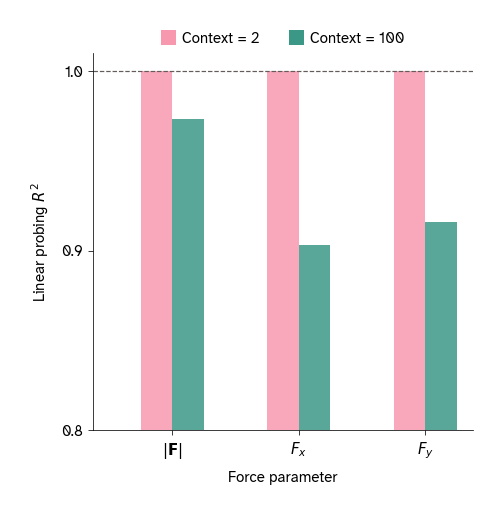

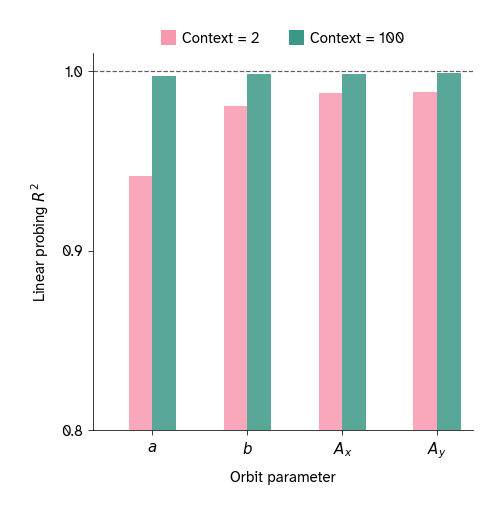

In [4]:
#| label: fig-phase-transition
#| fig-cap: "Best-layer linear-probing $R^2$ at the last input position, for context length 2 and context length 100."
#| fig-subcap:
#|   - "Newtonian targets: force magnitude $|\\mathbf{F}|$ and its components $F_x$ and $F_y$."
#|   - "Keplerian targets: the semi-major and semi-minor axes $a$ and $b$, and the two components of the Laplace-Runge-Lenz vector."
#| fig-alt:
#|   - "Grouped bars for three force targets. For every target the short-context bar reaches the top of the axis and the long-context bar falls below it."
#|   - "Grouped bars for four orbit-geometry targets. Here the ordering is reversed, with the long-context bar the taller of each pair."
#| layout-ncol: 2
#| code-fold: true
from analysis.data import load_trajectories, load_orbital_params
from analysis.probing import probe_model, best_r2

with contextlib.redirect_stdout(io.StringIO()):
    trajs    = np.asarray(load_trajectories(DATA_DIR, num_trajectories_needed=NUM_TRAJ))
    o_params = load_orbital_params(DATA_DIR, num_trajectories_needed=NUM_TRAJ)
    newton_2,   kepler_2   = probe_model(model_bs2,   trajs, o_params, 2,   n_probe=1000, seed=SEED)
    newton_100, kepler_100 = probe_model(model_bs100, trajs, o_params, 100, n_probe=1000, seed=SEED)

NEWTON = [('F_magnitude', r'$|\mathbf{F}|$'), ('Fx', r'$F_x$'), ('Fy', r'$F_y$')]
KEPLER = [('a', r'$a$'), ('b', r'$b$'), ('LRL_x', r'$A_x$'), ('LRL_y', r'$A_y$')]

PANEL = apc.mpl.FIGURE_SIZES_IN_INCHES['half_square']
for xlabel, items, p2, p100 in [
        ('force parameter', NEWTON, newton_2, newton_100),
        ('orbit parameter', KEPLER, kepler_2, kepler_100)]:
    targets = [t for t, _ in items]; ticklab = [l for _, l in items]
    r2_2   = [best_r2(p2,   t) for t in targets]
    r2_100 = [best_r2(p100, t) for t in targets]
    bw = 0.25; br1 = np.arange(len(targets))
    fig, ax = plt.subplots(figsize=PANEL)
    ax.bar(br1,      r2_2,   bw, color=C_CTX_2, alpha=0.85,  label='Context = 2')
    ax.bar(br1 + bw, r2_100, bw, color=C_CTX_100, alpha=0.85, label='Context = 100')
    ax.axhline(1, ls='--', color=ARC_DIAG, lw=1.2)
    ax.set_xlim(-0.5, len(targets) - 0.5)
    ax.set_ylim(0.8, 1.01)
    ax.set_yticks([0.8, 0.9, 1.0])
    ax.set_xticks(br1 + 0.5 * bw); ax.set_xticklabels(ticklab)
    ax.set_xlabel(xlabel); ax.set_ylabel(r'Linear probing $R^2$')
    # Bars span the full panel, so there is no free corner: seat the legend
    # above the axes rather than over the data.
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
    style_panel(ax)
    plt.show()


@fig-phase-transition shows that our retrained models exhibit the same probing characteristics reported by Liu et al. At context length 2, probing recovers Newtonian force components almost perfectly and above the orbital-geometry variables. At context length 100 that ranking flips, with the geometry variables best predicted. Notably, every target stays decodable at $R^2 > 0.9$ at both context lengths; the "transition" is a shift in which world model is best encoded, not a presence/absence switch[^1]. This is the same overall result Liu et al. identified, and our checkpoints reproduce it (consistent within run-to-run variance). From here on we treat these models as stand-ins for those of Liu et al.: they share the architecture, data-generation procedure, and training recipe, with the the removal of bias terms as the single change we introduced. Nonetheless we acknolwedge that they are ultimately retrained reimplementations. 

Confident that our models are behaving as expected, we now focus on using ELM to understand how input coordinates are combined to generate predictions in the short-context model. We restrict our analyses to this model for two reasons: 1) the limited number of input tokens makes it easier to interpret a smaller number of per-token Jacobians, and 2) the short-context model is the one that appears to learn the 'correct' Newtonian world model according to linear probing and is thus most interesting to unpack.

[^1]: We construct our probes on in-sample windows following the codebase of Liu et al. Out-of-sample probing results paint a similar picture, with the world model phase transition becoming starker. 

## Inside the short-context model

The probes tell us we can decode force variables using a linear transformation of the model's latent representations, but does the short-context model actually use Newtonian mechanics to make its predictions? With ELM, we can read out the actual computation: how the model turns the two positions it sees, $\mathbf r_{t-1}$ and $\mathbf r_t$, into its prediction $\hat{\mathbf r}_{t+1}$.

Here, we must address what it would mean for this computation to reflect a genuinely learned Newtonian world model. Since the training task is to predict a single future position, many heuristics can approximate it well without implementing the underlying physics. Simply copying the last position (persistence: $\hat{\mathbf r}_{t+1} = \mathbf r_t$) already achieves high $R^2$, since consecutive positions are close. More subtly, geometrically aware heuristics such as rotations could reproduce the *appearance* of a central force and even produce hidden states from which force components are linearly decodable, without computing the force law itself. Predictive accuracy, and even a passing linear probe, therefore, cannot establish that a model has learned Newtonian gravity. Our criterion is instead structural: does the recovered computation match that of a Newtonian mechanics-derived integrator? Since ELM recovers the exact linear combination of the two input positions used to form the prediction, we can compare it directly to a textbook solution of Newtonian orbital mechanics. Our reference is the second-order Verlet integrator:

$$\hat{\mathbf r}_{t+1} \;=\; \underbrace{2\,\mathbf r_t - \mathbf r_{t-1}}_{\text{inertial}}
\;+\;\underbrace{\Delta t^{2}\mathbf a(\mathbf r_t)}_{\text{gravitational}},
\qquad
\mathbf a(\mathbf r) \;=\; \ddot{\mathbf r} \;=\; -\,\frac{\mathbf r}{|\mathbf r|^{3}}$$

::: {.callout-note collapse="true" title="Deriving the Verlet integrator"}
Newton's second law gives the equation of motion
$\ddot{\mathbf r} = \mathbf a(\mathbf r)$, which for our system is
$\ddot{\mathbf r} = -\mathbf r/|\mathbf r|^3$. To integrate this forward in time from
two known positions, expand $\mathbf r$ as a Taylor series in both directions:

$$\mathbf r(t+\Delta t) = \mathbf r_t + \mathbf v_t\Delta t
+ \tfrac{1}{2}\mathbf a_t\Delta t^2 + O(\Delta t^3)$$

$$\mathbf r(t-\Delta t) = \mathbf r_t - \mathbf v_t\Delta t
+ \tfrac{1}{2}\mathbf a_t\Delta t^2 + O(\Delta t^3)$$

Adding the two equations cancels the velocity term exactly because the odd-power terms cancel and the even-power terms reinforce:

$$\hat{\mathbf r}_{t+1} \;=\; \underbrace{2\,\mathbf r_t - \mathbf r_{t-1}}_{\text{inertial}}
\;+\;\underbrace{\Delta t^{2}\,\mathbf a(\mathbf r_t)}_{\text{gravitational acceleration}},
\qquad
\mathbf a(\mathbf r) \;=\; -\,\frac{\mathbf r}{|\mathbf r|^{3}}$$
:::

The inertial part $2\,\mathbf r_t - \mathbf r_{t-1}$ is constant-velocity coasting. Rewritten as $\mathbf r_t + (\mathbf r_t - \mathbf r_{t-1})$, it reads "current position plus the last step's displacement." The final term is the small gravitational kick: the acceleration $\mathbf a$ of the setup's equation of motion, evaluated at the current position and held constant over one step of length $\Delta t$. A genuine force integrator therefore weights its two inputs by $(c_{t-1}, c_t) = (-1, 2)$ before the force correction. We call $(-1, 2)$ the **inertial point**. The Verlet integrator is the natural reference for a two-token model. Its inertial part requires exactly what two positions supply; a current position and displacement to a previous position, and its correction needs a single evaluation of the force at the current position.

How do we determine if the model is behaving like a Verlet integrator? While the gravitational term could be captured by any term in the ELM sum, inertia has to be encoded in the two content Jacobians because inertial extrapolation only works when applied to the coordinates of the previous planetary positions. Compounding this, inertia should also dominate the update in most orbital positions. **Consequently, a first-pass test for Verlet structure is to check whether the model carries the inertial point weights in the two relevant content Jacobians.** Each per-token block $J$ is $2\times2$, and its isotropic part $c = \mathrm{tr}(J)/D$ (here $D=2$) is the scalar by which that input position is uniformly scaled into the prediction. A genuine force integrator has to land *near* $(c_{t-1}, c_t) = (-1, 2)$.

In [5]:
#| code-fold: true
#| output: false
# Mechanistic analysis of the short-context (noise=0.1) model. Reuses the model and
# constants loaded in the intro setup
from analysis import elm as NT

model = model_bs2                 # the bs=2, noise=0.1 model from the intro

BLOCK_SIZE    = 2
N_WINDOWS     = 900               # Jacobian-based analyses (expensive; ~14 s per model).
                                  # 900 keeps ~180 windows per radius bin in the binned
                                  # panel below, enough for its bootstrap CIs to separate
                                  # the terms from the ideal kick.
N_WINDOWS_BEH = 4000              # behavioural analyses (cheap forward passes)
SPLIT  = 'test'
OFFSET = 0 if SPLIT == 'train' else NUM_TRAJ   # 50/50 train/test split, by trajectory

In [6]:
#| code-fold: true
#| output: false
# Per-token Jacobian blocks over N_WINDOWS real-orbit windows (slow; ~1-2 min).
# collect_terms also returns the size of each term in the ELM sum (the two
# content contributions and the positional one), used in the right-hand panel below.
all_blocks, coeffs, content, positional, radius, recon_err_max = NT.collect_terms(
    model, BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
T = coeffs.shape[1]
D = all_blocks.shape[-1]


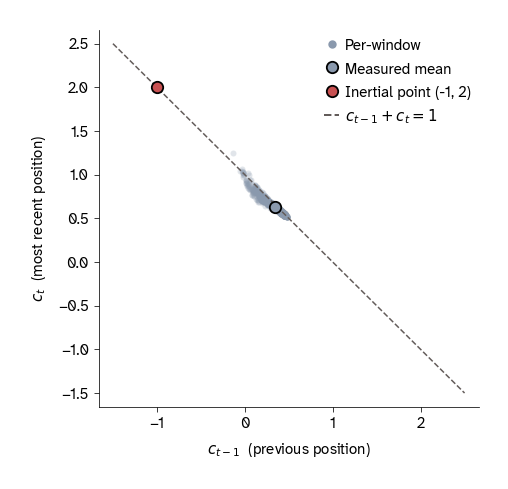

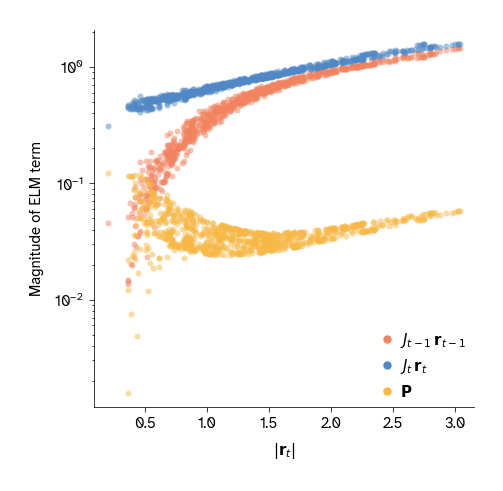

In [7]:
#| label: fig-verlet-coeff
#| fig-cap: "Isotropic Jacobian coefficients and ELM term magnitudes for the noisy short-context model."
#| fig-subcap:
#|   - "Isotropic coefficients of content Jacobians ($c_{t-1}, c_t$) plotted for a sample of orbital windows. One point per window, with the mean marked. The red circle is the inertial point (-1, 2) of a Verlet integrator, and the dashed line is $c_{t-1} + c_t = 1$."
#|   - "The magnitude of each of the three terms in the ELM sum for the same windows, against $|\\mathbf{r}_t|$, on a log axis."
#| fig-alt:
#|   - "Scatter in the plane of the two isotropic coefficients. The points form a tight cluster where both coefficients are positive, close to the dashed constraint line and far from the marked inertial point in the upper left."
#|   - "Term magnitudes against radius on a logarithmic axis. The two content terms rise with radius and converge, and the positional term lies far below both across the whole range."
#| layout-ncol: 2
#| code-fold: true
PANEL = apc.mpl.FIGURE_SIZES_IN_INCHES['half_square']

fig, ax = plt.subplots(figsize=PANEL)
NT.plot_coefficient_plane(ax, coeffs)
style_panel(ax)
plt.show()

# The coefficient analysis above uses the content Jacobians only, so show what the
# omitted positional term is worth alongside them.
fig, ax = plt.subplots(figsize=PANEL)
NT.plot_term_magnitudes(ax, content, positional, radius)
style_panel(ax)
plt.show()

@fig-verlet-coeff-1 shows that the content Jacobians do not sit near the inertial point for any sampled prediction windows. Rather, the model's two positive weights make its prediction a weighted average of its inputs. Consequently, the model is unlikely to be computing textbook Newtonian integration, despite the high decodability of Newtonian force components from its internal representations. 

To better understand how the model computes its prediction, we also plotted the absolute magnitudes of the three vectors that the ELM identity sums (the two content terms and the total positional term) against the current radius in @fig-verlet-coeff-2. This view reveals that the most recent token dominates the prediction at small radii, whereas the two content terms become comparable at larger radii. The positional term is tiny across the whole distribution, a couple of percent of the prediction. The massive overweighting of the most recent position further confirms a lack of Verlet-like computation in the model.

If the model is not approximating a Newtonian integrator, which internal logic has it arrived at to make predictions? A guess can be made by inspecting the average of the entire Jacobian block (of both tokens) for a small sample of predictions. The two matrices below show the averaged per-token blocks: both look like scaled rotation matrices containing equal diagonals and equal-and-opposite off-diagonals[^3], i.e. $J \approx c\,R(\theta)$. The model does not push $\mathbf r_t$ forward; rather it likely turns it.

[^3]:Note that this rotational structure emerges so cleanly because all simulated orbits have an anti-clockwise direction, so the off-diagonal sign changes do not cancel out.


In [8]:
#| code-fold: true

from analysis.elm import rotation_decompose

mean_recent = all_blocks[:, T-1].mean(0)
mean_prev   = all_blocks[:, T-2].mean(0)
sc_r, _, angm_r, _ = rotation_decompose(mean_recent)
sc_p, _, angm_p, _ = rotation_decompose(mean_prev)

from IPython.display import Markdown, display

def to_latex_matrix(M, name):
    return f"""
$$
{name} = \\begin{{pmatrix}}
{M[0,0]:+.3f} & {M[0,1]:+.3f} \\\\
{M[1,0]:+.3f} & {M[1,1]:+.3f}
\\end{{pmatrix}}
$$
"""

display(Markdown(to_latex_matrix(mean_recent, r"\bar{J}_t")))
display(Markdown(to_latex_matrix(mean_prev,   r"\bar{J}_{t-1}")))


$$
\bar{J}_t = \begin{pmatrix}
+0.623 & -0.127 \\
+0.128 & +0.628
\end{pmatrix}
$$



$$
\bar{J}_{t-1} = \begin{pmatrix}
+0.345 & -0.097 \\
+0.103 & +0.346
\end{pmatrix}
$$


We can test this more formally by decomposing the linear transformations encoded by the content Jacobians. A $2\times2$ matrix has four degrees of freedom, which map onto four basis matrices that are mutually orthogonal under the Frobenius inner product $\langle A, B\rangle = \mathrm{tr}(A^\top B)$:

$$J = \underbrace{c \begin{bmatrix}1&0\\0&1\end{bmatrix}}_{\text{isotropic}} +
      \underbrace{a \begin{bmatrix}0&-1\\1&0\end{bmatrix}}_{\text{rotation}} +
      \underbrace{g_1 \begin{bmatrix}1&0\\0&-1\end{bmatrix}}_{\text{axis shear}} +
      \underbrace{g_2 \begin{bmatrix}0&1\\1&0\end{bmatrix}}_{\text{diagonal shear}}$$

The four coefficients are read directly off the matrix entries:

$$c = \frac{J_{00} + J_{11}}{2}, \quad
a   = \frac{J_{10} - J_{01}}{2}, \quad
g_1 = \frac{J_{00} - J_{11}}{2}, \quad
g_2 = \frac{J_{01} + J_{10}}{2}$$

Geometrically each component acts differently on a vector $\mathbf r$:

- **Isotropic** $c$: uniform scaling — pushes radially inward or outward equally in all directions (already used in our test for inertia).

- **Rotation** $a$: rotates $90^\circ$ and scales — a pure turn with no stretching.

- **Axis shear** $g_1$: stretches along $x$ and compresses along $y$ (or vice versa) — deforms without rotating.

- **Diagonal shear** $g_2$: stretches along the $45°$ diagonal and compresses the perpendicular — a second independent shear mode.

With this full decomposition in hand, we calculate a "rotation score":

$$\frac{a^2}{a^2 + g_1^2 + g_2^2}$$

This score has a natural interpretation; it is the fraction of the *direction-changing* action (everything except the isotropic scale) that is a clean rotation rather than a shear distortion. A score near 1 means the block turns vectors without deforming them while a score near 0 means shear dominates. If the model has learned a rotation-based strategy we expect this score to be near 1 for both tokens, and the generator coefficient $a$ to track the gravitational acceleration magnitude across the orbit.


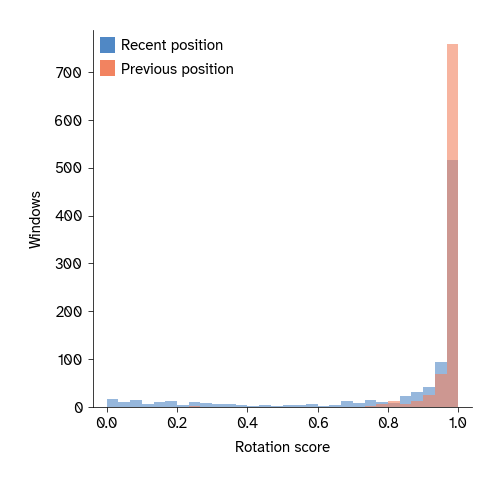

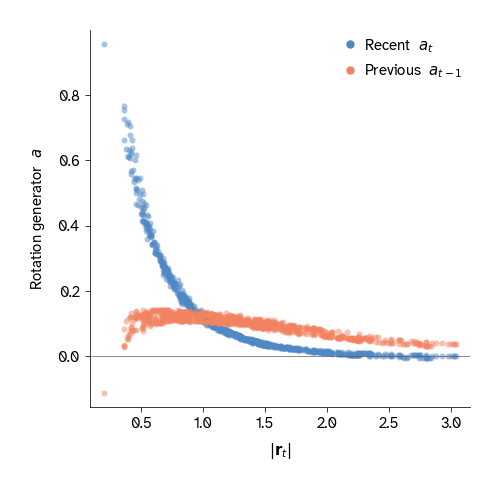

In [9]:
#| label: fig-rotation-generators
#| fig-cap: "Per-window rotation structure of the noisy short-context model's two content blocks."
#| fig-subcap:
#|   - "Distribution of the rotation score $a^2/(a^2 + g_1^2 + g_2^2)$, the fraction of each block's direction-changing action that is rotation rather than shear."
#|   - "The rotation generator $a = (J_{10} - J_{01})/2$, the signed strength of the block's sideways push, against the current radius."
#| fig-alt:
#|   - "Two overlapping histograms of the rotation score, both piled up against the right-hand edge of the axis."
#|   - "The rotation generator against radius for both blocks. The recent-position series grows steadily in magnitude with radius while the previous-position series stays comparatively flat."
#| layout-ncol: 2
#| code-fold: true

mean_recent = all_blocks[:, T-1].mean(0)
mean_prev   = all_blocks[:, T-2].mean(0)
ds_r, a_r, ang_r, score_r = rotation_decompose(all_blocks[:, T-1])
ds_p, a_p, ang_p, score_p = rotation_decompose(all_blocks[:, T-2])
w_r    = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
radius = np.linalg.norm(w_r[:, T-1, :], axis=1)

PANEL    = apc.mpl.FIGURE_SIZES_IN_INCHES['half_square']
C_RECENT = C_TOKEN_RECENT
C_PREV   = C_TOKEN_PREV

fig, ax = plt.subplots(figsize=PANEL)
ax.hist(score_r, bins=30, range=(0, 1), color=C_RECENT, alpha=0.6, label='recent position')
ax.hist(score_p, bins=30, range=(0, 1), color=C_PREV,   alpha=0.6, label='previous position')
ax.set_xlabel('rotation score')
ax.set_ylabel('windows')
ax.legend(frameon=False)
style_panel(ax)
plt.show()

fig, ax = plt.subplots(figsize=PANEL)
ax.axhline(0, color=ARC_DIAG, lw=0.7)
ax.scatter(radius, a_r, alpha=0.5, color=C_RECENT, label=r'recent  $a_t$')
ax.scatter(radius, a_p, alpha=0.5, color=C_PREV,   label=r'previous  $a_{t-1}$')
ax.set_xlabel(r'$|\mathbf{r}_t|$')
ax.set_ylabel(r'rotation generator  $a$')
ax.legend(frameon=False)
style_panel(ax)
plt.show()


@fig-rotation-generators-1 shows the rotation score sits near 1 for both tokens, implying each block is a near-pure scaled rotation, not a shear or reflection. @fig-rotation-generators-2 demonstrates that the generator *a* scales with radius, for the more recent input planetary position, suggesting that the model might be adjusting the rotation to match gravitational force (although at larger radii the prediction becomes a more even blend of both input tokens). Together with our results in @fig-verlet-coeff we now have confirmation that the model heavily leans on the current planet position at small radii, and applies a rotational transformation to it that scales with gravitational acceleration. The precise results of the scaled rotation will depend both on the generator and isotropic components (and how their effects are combined across the two tokens). To avoid this complexity, we next use a behavioral test to further test the rotation hypothesis.


### The noisy short-context model runs a local circular-orbit heuristic

Inspecting the Jacobians suggests the model turns $\mathbf r_t$, but what sets the angle? Kepler's second law (a planet sweeps equal areas in equal times) fixes the per-step angle of a real orbit to $\Delta\theta = L_z\,\Delta t / r^2$, where $L_z$ is the angular momentum, the conserved rate at which the position vector sweeps out area. So the true angle should grow like $1/r^2$ (faster near the sun) but also scale with $L_z$ (which differs from orbit to orbit). Our sequences carry positions and not velocities, so we estimate the numerator of that expression directly from the in-window displacement, $L_z\,\Delta t \approx \mathbf r_t \times (\mathbf r_t - \mathbf r_{t-1})$ — the quantity that actually sets the per-step angle. Below we use a behavioral test to compare the model's per-step rotation against both, and against the radial in-and-out motion a real orbit undergoes.


In [10]:
#| code-fold: true
#| output: false
# Behavioural rotation statistics over many cheap forward passes.
behav = NT.rotation_behavioral(model, BLOCK_SIZE, N_WINDOWS_BEH, seed=SEED, offset=OFFSET)


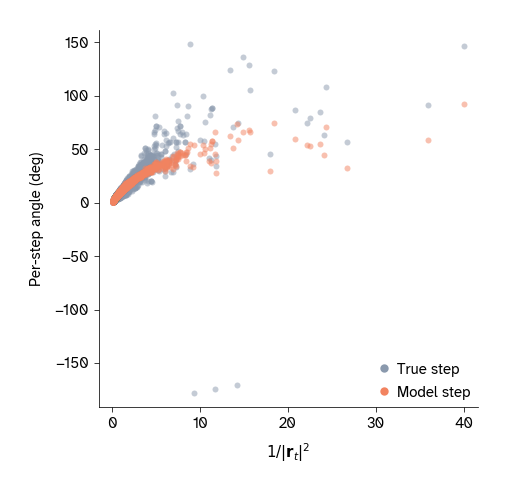

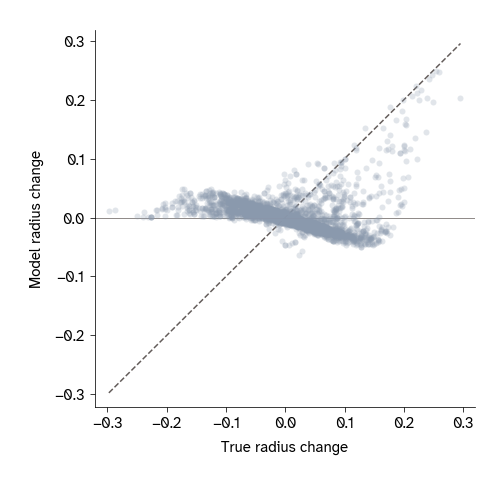

In [11]:
#| label: fig-kepler2
#| fig-cap: "Per-step motion of the true orbit against the model's, for the noisy short-context model."
#| fig-subcap:
#|   - "Per-step rotation angle against $1/|\\mathbf{r}_t|^2$, for the true orbit and for the model's prediction."
#|   - "The true per-step change in radius against the model's, with the identity dashed."
#| fig-alt:
#|   - "Per-step angle against inverse-square radius. The true values fan out into a broad band, while the model's follow a single narrow curve rising with the same variable."
#|   - "True against model radius change. The model's values sit in a narrow, flat horizontal band instead of along the dashed identity line."
#| layout-ncol: 2
#| code-fold: true
PANEL = apc.mpl.FIGURE_SIZES_IN_INCHES['half_square']

inv_r2 = behav['inv_r2']
at, am = np.degrees(behav['ang_true']), np.degrees(behav['ang_model'])
fig, ax = plt.subplots(figsize=PANEL)
ax.scatter(inv_r2, at, alpha=0.5, color=C_TRUE,  label='true step')
ax.scatter(inv_r2, am, alpha=0.5, color=C_MODEL, label='model step')
ax.set_xlabel(r'$1/|\mathbf{r}_t|^2$')
ax.set_ylabel('per-step angle (deg)')
ax.legend(frameon=False)
style_panel(ax)
plt.show()

dtr, dmr = behav['dr_true'], behav['dr_model']
lo, hi = float(min(dtr.min(), dmr.min())), float(max(dtr.max(), dmr.max()))
fig, ax = plt.subplots(figsize=PANEL)
ax.plot([lo, hi], [lo, hi], ls='--', lw=1.5, color=ARC_DIAG, zorder=1)
ax.axhline(0, color=ARC_DIAG, lw=0.7, zorder=1)
ax.scatter(dtr, dmr, alpha=0.25, color=ARC_VIBE, zorder=2)
ax.set_xlabel('True radius change')
ax.set_ylabel('Model radius change')
style_panel(ax)
plt.show()


@fig-kepler2-1 shows that the model's rotation angle does indeed monotonically grow with $1/r^2$ (i.e. it speeds up near the sun), but unlike the true orbit, it's a single tight curve which mostly ignores angular momentum (the orange points show little vertical spread, while the true points fan out). Further, @fig-kepler2-2 shows that the model barely changes the radius step-to-step (mostly encoding a small bias towards shrinking the radius), roughly keeping the planet on a circular orbit. Together, these results suggest the model isn't tracking the real orbit; instead, it treats each step as if the planet were on a local circular orbit of the current radius. A circular orbit at radius $r$ sweeps $\Delta\theta = \Delta t / r^{3/2}$ per step (with $GM=1$). If that is the heuristic, the model's rotation should match this curve, a prediction we can also test.


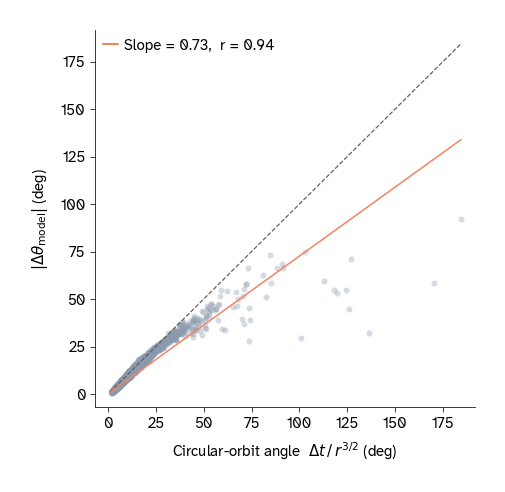

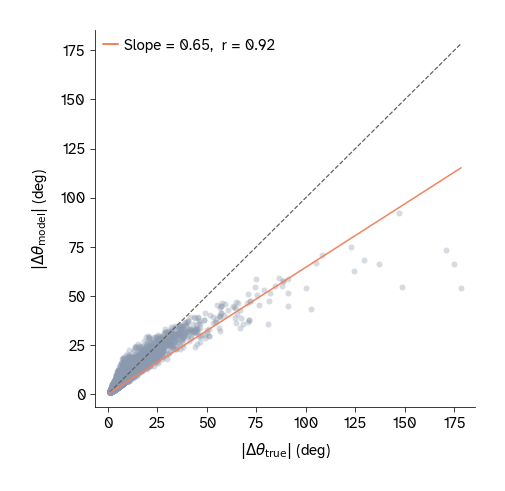

In [12]:
#| label: fig-circular
#| fig-cap: "The model's per-step rotation angle against two references. The dashed line is the identity; the annotation gives the fitted slope and correlation."
#| fig-subcap:
#|   - "Against the angle a circular orbit of the same radius sweeps."
#|   - "Against the true orbital angle."
#| fig-alt:
#|   - "Model angle against the circular-orbit prediction. Points track the dashed identity closely at small angles and fall increasingly below it at larger ones."
#|   - "The same against the true orbital angle, where the points are more scattered and sit further below the identity."
#| layout-ncol: 2
#| code-fold: true

r_t          = behav['inv_r2'] ** (-0.5)
ang_circular = np.degrees(DT / r_t**1.5)
am_abs, at_abs = np.abs(np.degrees(behav['ang_model'])), np.abs(np.degrees(behav['ang_true']))

ang_c_m, am_m, at_m = ang_circular, am_abs, at_abs
corr_m,   slope_m   = np.corrcoef(ang_c_m, am_m)[0, 1], np.polyfit(ang_c_m, am_m, 1)[0]
corr_beh, slope_beh = np.corrcoef(at_m,   am_m)[0, 1], np.polyfit(at_m,   am_m, 1)[0]

PANEL = apc.mpl.FIGURE_SIZES_IN_INCHES['half_square']

for xdata, ydata, corr, slope, xlabel in [
    (ang_c_m, am_m, corr_m,   slope_m,
     r'Circular-orbit angle  $\Delta t\,/\,r^{3/2}$ (deg)'),
    (at_m,    am_m, corr_beh, slope_beh,
     r'$|\Delta\theta_{\text{true}}|$ (deg)'),
]:
    fig, ax = plt.subplots(figsize=PANEL)
    lo = float(min(xdata.min(), ydata.min()))
    hi = float(max(xdata.max(), ydata.max()))
    xs = np.linspace(lo, hi, 100)
    ax.scatter(xdata, ydata, alpha=0.35, color=ARC_VIBE, linewidths=0, zorder=1)
    ax.plot([lo, hi], [lo, hi], color=ARC_DIAG, lw=1.2, ls='--', zorder=2)
    ax.plot(xs, slope * xs, color=ARC_CORAL, lw=1.5,
            label=f'slope = {slope:.2f},  r = {corr:.2f}', zorder=3)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(r'$|\Delta\theta_{\text{model}}|$ (deg)')
    ax.legend(frameon=False)
    style_panel(ax)
    plt.show()


@fig-circular supports the circular rotation heuristic interpretation. The model's rotation angle tracks the circular-orbit prediction better than the true orbital angle, deviating only at extreme angles near perihelion where large jumps in orbital position happen relative to time-slices used in our simulations. The fitted slope is 0.73 rather than 1, suggesting the heuristic lags a true circular orbit. Compared to the true orbit angle, the model has a poorer fit (corr = 0.92) but more importantly a significantly reduced scaling (slope = 0.65). The difference in fit is particularly notable for orbital angle steps below $50^\circ$, where the circular orbit matches the model behavior almost perfectly, demonstrating that a local circular orbit matches the model's behavior much closer than a properly fit ellipse.

So the noise-robust short-context model has almost certainly not learned Newtonian gravity. Instead, it has learned a local circular-orbit heuristic: rotate the most recent position by approximately the angle that a circular orbit of that radius would sweep out, while holding the radius mostly fixed. This is a smooth approximation that captures the $r^{-3/2}$ angular speed-up of a circular orbit but discards angular momentum and radial dynamics. This solution works in the context of the training task because the model is only ever trained to predict the position of one future timepoint (i.e. a rollout loss is not used), so a heuristic for a small time step can work reasonably well. The apparent noise-tolerance of this strategy is also a key as to why the model didn't (and probably *couldn't*) learn a Newtonian integrator, since solutions like Verlet are sensitive to input error. The gravitational correction a second-order integrator has to fit enters the position update scaled by $\Delta t^{2}$, which makes it small compared with the injected noise over most of the orbit. The Newtonian signal a model would need to learn therefore sits largely below the noise floor. Could the model learn Verlet integration if noise were removed? We test this question in the next section.


## Without training noise a more Newtonian world model emerges

In the previous section, we established that the noisy short-context model settled for a smooth, noise-robust rotational heuristic. Naturally, we next wanted to ask if removing the denoising objective during training might allow the model to learn a more Newtonian solution. To test this, we repeat our analyses on a noiseless short-context model (`noise_scale = 0.0`). Freed from having to tolerate corrupted context, this model should be able to afford the sharp finite-difference computation of a genuine Newtonian force integrator. As before, our first test is to see if the content Jacobians' isotropic coefficients settle near the inertial point.


In [13]:
#| code-fold: true
#| output: false
# Switch to the NOISELESS model (noise_scale = 0.0) and recompute its Jacobian blocks.
CKPT_BS2_NL = f'{CHECKPOINT_DIR}/model_block_size_{BLOCK_SIZE}_num_trajectories_{NUM_TRAJ}_noise_scale_0.0.pt'
with contextlib.redirect_stdout(io.StringIO()):
    model_noiseless, _ = load_from_checkpoint(CKPT_BS2_NL, device='cpu'); model_noiseless.eval()
    all_blocks, coeffs, content, positional, radius, recon_err_max = NT.collect_terms(
        model_noiseless, BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
T = coeffs.shape[1]; D = all_blocks.shape[-1]


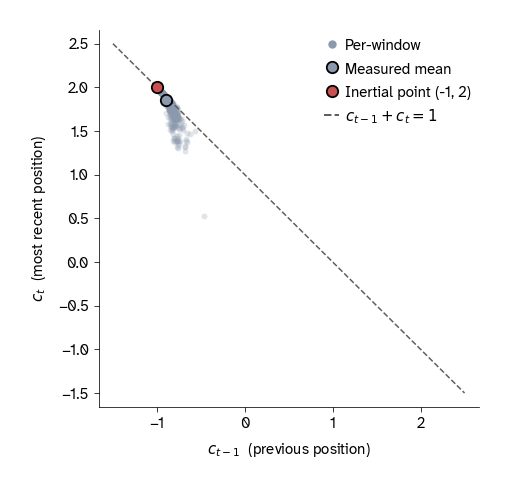

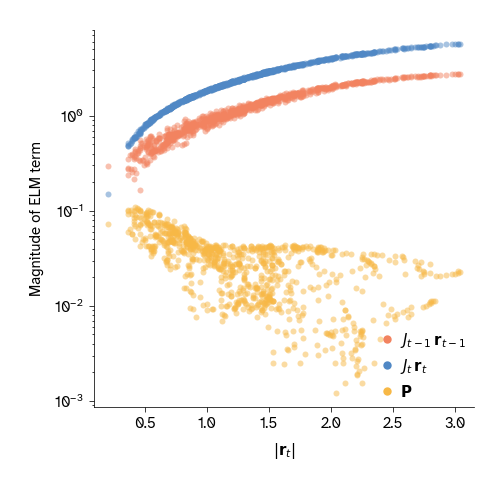

In [14]:
#| label: fig-verlet-noiseless
#| fig-cap: "Isotropic Jacobian coefficients and ELM term magnitudes for the noiseless short-context model."
#| fig-subcap:
#|   - "Isotropic coefficients of content Jacobians ($c_{t-1}, c_t$) plotted for a sample of orbital windows. One point per window, with the mean marked. The red circle is the inertial point (-1, 2) of a Verlet integrator, and the dashed line is $c_{t-1} + c_t = 1$."
#|   - "The magnitude of each of the three terms in the ELM sum for the same windows, against $|\\mathbf{r}_t|$, on a log axis."
#| fig-alt:
#|   - "Scatter in the plane of the two isotropic coefficients. The cluster sits close to the marked inertial point in the upper left, with one coefficient negative and the other positive."
#|   - "Term magnitudes against radius on a logarithmic axis. The recent content term sits consistently above the previous one by a roughly constant factor, with the positional term far below both."
#| layout-ncol: 2
#| code-fold: true
PANEL = apc.mpl.FIGURE_SIZES_IN_INCHES['half_square']

fig, ax = plt.subplots(figsize=PANEL)
NT.plot_coefficient_plane(ax, coeffs)
style_panel(ax)
plt.show()

# The coefficient analysis above uses the content Jacobians only, so show what the
# omitted positional term is worth alongside them.
fig, ax = plt.subplots(figsize=PANEL)
NT.plot_term_magnitudes(ax, content, positional, radius)
style_panel(ax)
plt.show()


@fig-verlet-noiseless-1 shows the noiseless model's isotropic coefficients at $(c_{t-1}, c_t) \approx (-0.9, +1.85)$, much closer to the inertial point $(-1, 2)$ than the noisy model (@fig-verlet-coeff). This model seems to extrapolate forward like a genuine second-order integrator, rather than blending its two inputs. The absolute magnitudes of the ELM vector terms are also correspondingly changed (@fig-verlet-noiseless-2). There's a consistent difference in the weighting of the two content terms that is relatively radius invariant, the most current input coordinate ($\mathbf r_t$) being weighted roughly twice as much as the previous one ($\mathbf r_{t-1}$). Similar to the noisy model, the positional term is relatively weak in magnitude, although we'll show later that it does make an important contribution to the final prediction.

The physics that should make this model explicitly Newtonian rather than merely inertial will live in the residual from the inertial point. In the next step, we verify behaviorally that this correction approximately captures the Newtonian gravitational kick $-\Delta t^2\,\mathbf r_t/|\mathbf r_t|^3$, and then examine how that residual is organized across the model's two input tokens and positional embedding terms.


### The noiseless model captures the gravitational kick

As a first step, we behaviorally test (with no reference to the detached Jacobian) whether the model's non-inertial output actually captures Newtonian gravity. From the model's own second difference, $\mathbf a_{\text{eff}} = (\hat{\mathbf r}_{t+1} - 2\,\mathbf r_t + \mathbf r_{t-1})/\Delta t^2$, a genuine force integrator would give $\mathbf a_{\text{eff}} = -\mathbf r_t/|\mathbf r_t|^3$ ($GM=1$).


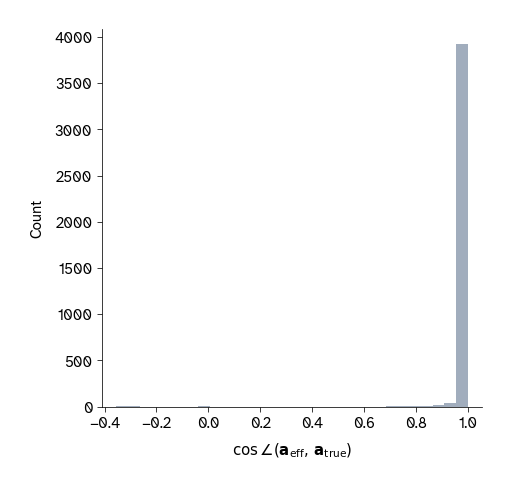

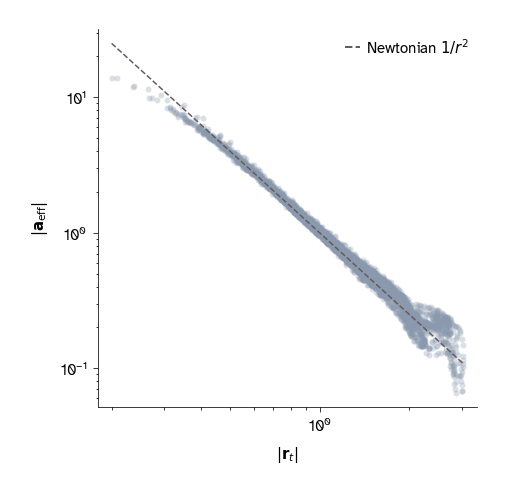

In [15]:
#| label: fig-newton-behavioral
#| fig-cap: "Behavioural test of the noiseless model's non-inertial output, computed from the model's own predictions with no reference to the Jacobian: $\\mathbf{a}_{\\text{eff}} = (\\hat{\\mathbf{r}}_{t+1} - 2\\,\\mathbf{r}_t + \\mathbf{r}_{t-1})/\\Delta t^2$."
#| fig-subcap:
#|   - "Distribution of the cosine between $\\mathbf{a}_{\\text{eff}}$ and true Newtonian gravity ($\\mathbf{a}_{\\text{true}}$) at the same position."
#|   - "$\\mathbf{a}_{\\text{eff}}$ against $|\\mathbf{r}_t|$ on log axes, with the Newtonian $1/r^2$ reference dashed."
#| fig-alt:
#|   - "Histogram of cosine similarity between true gravity and the observed deviation from inerta, concentrated in a narrow peak against the right-hand edge of the axis."
#|   - "Effective acceleration magnitude against radius on logarithmic axes. The points fall along a straight declining line that closely follows the dashed inverse-square reference."
#| layout-ncol: 2
#| code-fold: true
# Attribution-free -- uses the second difference of the model's OWN prediction, so it is
# invariant to how gravity is split across J_t / J_{t-1}:
#   a_eff = (r_hat_{t+1} - 2 r_t + r_{t-1}) / dt^2     (Verlet: a_eff = -r_t/|r_t|^3, GM=1)
# Tests (1) does a_eff point at the focus?  (2) does |a_eff| ~ 1/r^2?
N_ACC = 4000
mdl   = model_noiseless                      # the noiseless (Verlet-like) model

w = NT.sample_orbit_windows(BLOCK_SIZE, N_ACC, seed=SEED, offset=OFFSET)   # (n,2,2)
r_prev, r_t = w[:, -2, :], w[:, -1, :]

mdtype = next(mdl.parameters()).dtype
with torch.no_grad():
    pred = mdl(torch.tensor(w).to(mdtype))[0][:, -1, :].double().numpy()   # (n,2)

a_eff  = (pred - 2*r_t + r_prev) / DT**2      # model's effective acceleration
r      = np.linalg.norm(r_t, axis=1)
a_true = -r_t / r[:, None]**3                 # Newtonian gravity at r_t (GM=1)

# (1) direction: cos between measured and Newtonian (focus-directed) acceleration
cos_dir = (a_eff*a_true).sum(1) / (np.linalg.norm(a_eff,axis=1)*np.linalg.norm(a_true,axis=1) + 1e-30)
# (2) magnitude scaling: |a_eff| ~ r^p; Newtonian p=-2
mag = np.linalg.norm(a_eff, axis=1)
slope, intercept = np.polyfit(np.log(r), np.log(mag), 1)

PANEL = apc.mpl.FIGURE_SIZES_IN_INCHES['half_square']

fig, ax = plt.subplots(figsize=PANEL)
ax.hist(cos_dir, bins=30, alpha=0.8, color=ARC_VIBE, edgecolor='white')
ax.set_xlabel(r'$\cos\angle(\mathbf{a}_{\text{eff}},\,\mathbf{a}_{\text{true}})$')
ax.set_ylabel('count')
style_panel(ax)
plt.show()

fig, ax = plt.subplots(figsize=PANEL)
ax.scatter(r, mag, alpha=0.3, color=ARC_VIBE)
rr = np.linspace(r.min(), r.max(), 100)
ax.plot(rr, rr**-2.0, ls='--', lw=1.5, color=apc.mud, label=r'Newtonian $1/r^2$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$|\mathbf{r}_t|$')
ax.set_ylabel(r'$|\mathbf{a}_{\text{eff}}|$')
ax.legend(frameon=False)
style_panel(ax)
plt.show()


@fig-newton-behavioral confirms the model's effective acceleration points at the sun and scales inverse-square ($|\mathbf a_{\text{eff}}| \sim r^{-1.9}$ vs. Newtonian $r^{-2}$). Consequently, the noiseless model will functionally capture the angular momentum that the noisy model was blind to, correctly adjusting the predicted per-step angle and radius change far more accurately (at least with no extended rollout, more on that below). Given we now know the gravitational kick is behaviorally present in this model, we next use the detached Jacobian to pinpoint how it is computed across the input components.


### What supplies the gravitational kick

The behavioral test tells us that the noiseless model's departure from inertial coasting matches Newtonian gravity. ELM, however, gives us the ability to go a step further and ask *how* that kick is produced by inspecting the terms the model actually adds up. Subtracting Verlet's inertial part from the content Jacobians in the ELM identity leaves three terms:

$$\underbrace{\hat{\mathbf r}_{t+1} - (2\,\mathbf r_t - \mathbf r_{t-1})}_{\text{deviation from inertia}} \;=\; \underbrace{\mathrm{d}J_t\,\mathbf r_t \;+\; \mathrm{d}J_{t-1}\,\mathbf r_{t-1}}_{\text{content residual}} \;+\; \underbrace{\mathbf P}_{\text{positional}}$$

with $\mathrm{d}J_t = J_t - 2I$, $\mathrm{d}J_{t-1} = J_{t-1} + I$, and $\mathbf P$ the positional term of the ELM identity. One term per input token plus the positional one.

Two features of the identity matter for what follows. First, it is a sum of vectors. The $\mathrm{d}J$ residual Jacobians are *operators*, and they only become contributions once they act on their inputs, so the three terms have to be compared as products $\mathrm{d}J\,\mathbf r$ rather than as matrices. Second, the positional term is not negligible at this scale. It is a couple of percent of the prediction (@fig-verlet-noiseless-2), but the deviation from inertia is itself some forty times smaller than the prediction, and measured against that quantity $\mathbf P$ is comparable in size to the gravitational kick. For simplicity in this section, we collapse both content residual terms ($\mathrm{d}J_t\,\mathbf r_t \;+\; \mathrm{d}J_{t-1}\,\mathbf r_{t-1}$) together (the same as our treatment of the positional embedding terms so far).


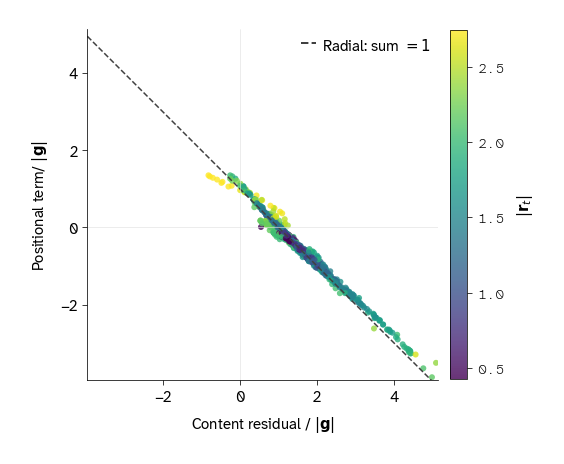

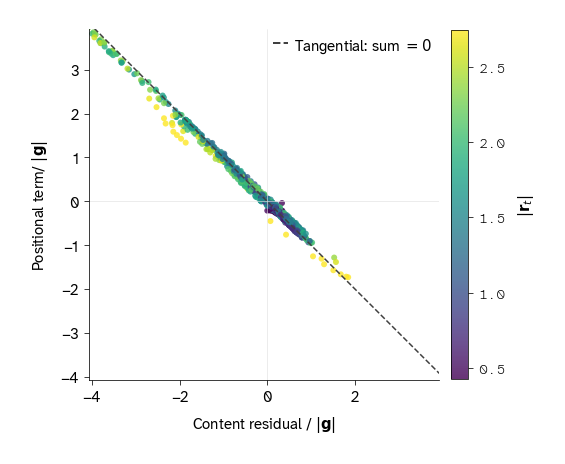

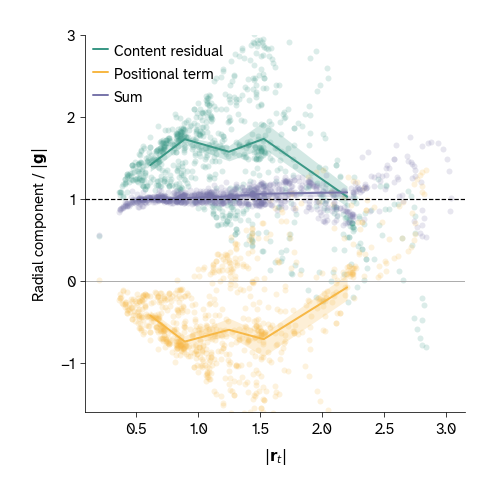

In [16]:
#| label: fig-kick-terms
#| fig-cap: "The noiseless model's deviation from inertial coasting, split into the content residual $(\\mathrm{d}J_t\\,\\mathbf{r}_t + \\mathrm{d}J_{t-1}\\,\\mathbf{r}_{t-1})$ and the positional term $\\mathbf{P}$. Points are coloured by $|\\mathbf{r}_t|$."
#| fig-subcap:
#|   - "Radial component, resolved in each window's own gravity frame: the positional contribution against the content one, in units of $|\\mathbf{g}|$. The dashed line marks where the pair sums to 1, as reproducing gravity requires."
#|   - "Tangential component, same axes. The dashed line marks where the pair sums to 0."
#|   - "The radial division against $|\\mathbf{r}_t|$ directly, with medians over five quantile bins and 95% bootstrap confidence intervals of the median."
#| fig-alt:
#|   - "Positional against content contribution for the radial component. Points lie strung out along the dashed constraint line rather than concentrated at any one place on it."
#|   - "The same for the tangential component, with points again spread along the dashed constraint line and scattering to either side of the origin."
#|   - "The two contributions against radius. The content median runs above the gravity line and the positional median below zero, the two converging as radius grows."
#| layout-ncol: 2
#| code-fold: true
from IPython.display import display
from analysis.elm import kick_terms, plot_kick_terms

w_kick = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
assert len(w_kick) == len(all_blocks), f"{len(w_kick)} vs {len(all_blocks)}"

# The ELM identity is exact, so the three terms must reproduce the model's own
# deviation from inertial coasting. Check that rather than trust it -- it catches
# any index or sign slip in the dJ products.
_kt = kick_terms(content, positional, w_kick, DT)
_mdtype = next(model_noiseless.parameters()).dtype
with torch.no_grad():
    _pred = model_noiseless(torch.tensor(w_kick).to(_mdtype))[0][:, -1, :].double().numpy()
_inertia = 2 * w_kick[:, T - 1, :] - w_kick[:, T - 2, :]
assert np.abs(_kt['total'] - (_pred - _inertia)).max() < 1e-6

PANEL = apc.mpl.FIGURE_SIZES_IN_INCHES['half_square']
figs  = [plt.subplots(figsize=PANEL) for _ in range(3)]
kick  = plot_kick_terms([a for _, a in figs], content, positional, w_kick, DT)
for f, a in figs:
    style_panel(a, colorbar_exists=bool(a.collections))
    display(f)
plt.close('all')


@fig-kick-terms shows that both the content residuals and the positional embeddings are required to reconstruct the correct gravitational pull. Each panel resolves one component of the deviation in that window's own gravity frame, radial along the ideal kick (toward the star), and tangential (perpendicular error), and plots what each ELM term supplies. Gravity requires the radial pair to sum to 1 and the tangential pair to sum to 0, which puts each component on a line of slope -1; the dashed lines are those two constraints. Both components have points scattered across their lines, demonstrating how the combination of **all** terms is used to capture Newtonian gravity.

Radially, the content residual on average oversupplies roughly 1.5× the required sunward pull (@fig-kick-terms-1), which is countered by the positional term, trimming the overshoot. Tangentially, where gravity should contribute nothing at all, each term carries a sizeable sideways push whose direction varies from window to window, and the two annihilate (@fig-kick-terms-2). @fig-kick-terms-3 plots the radial division against radius directly. Wherever $|\mathbf r_t|<1$ the content residual consistently oversupplies the gravitational kick, which is countered by the positional embedding terms. At larger radii ($|\mathbf r_t|>1$), there is more variability in the contributions of the two types of terms, with the positional embedding at times contributing positively to boost an underpowered content residual kick, and in even rarer cases where the content residual contributes a negative (outward) radial pull.

So the gravitational kick is assembled by cancellation across the positional and content residual components. This final piece of the puzzle demonstrates that the model captures Newtonian gravity through different components across windows, highlighting the context-based nature of how the same underlying principles of the world model are actually enacted across inputs. 

The two residual operators themselves turn out to be near-negations of one another, $\mathrm{d}J_t + \mathrm{d}J_{t-1} \approx 0$, so the local map is translation-equivariant; and each is a scaled rotation. We describe them below for interest.

:::  {.callout-note collapse="true" title="What the two residual operators look like"}

Here we highlight the structure of the content Jacobian deviations from inertia, $\mathrm{d}J_t = J_t - 2I$ and $\mathrm{d}J_{t-1} = J_{t-1} + I$.

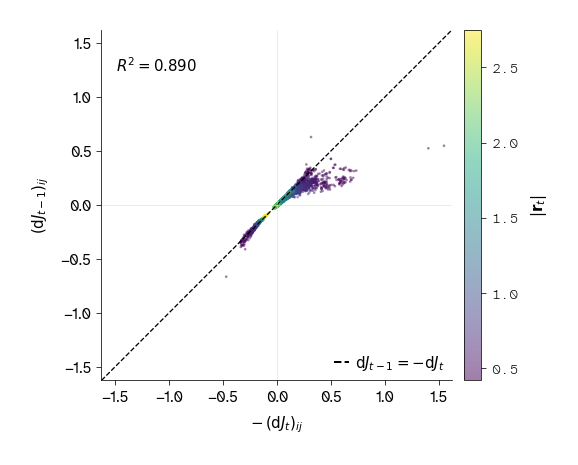

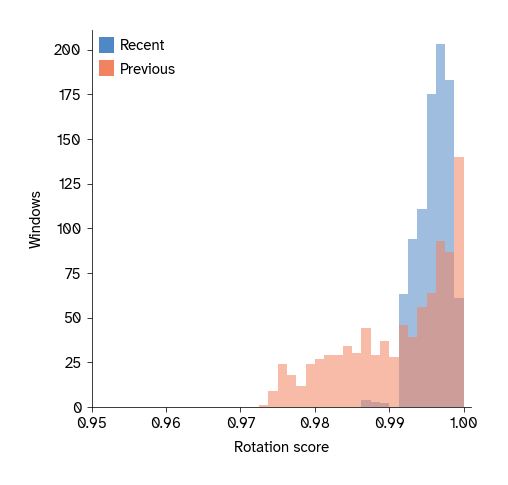

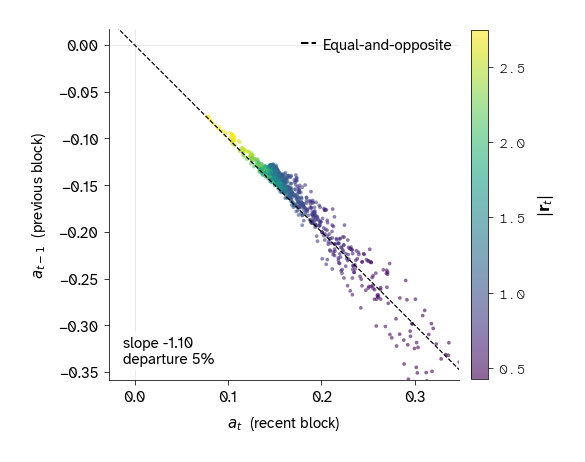

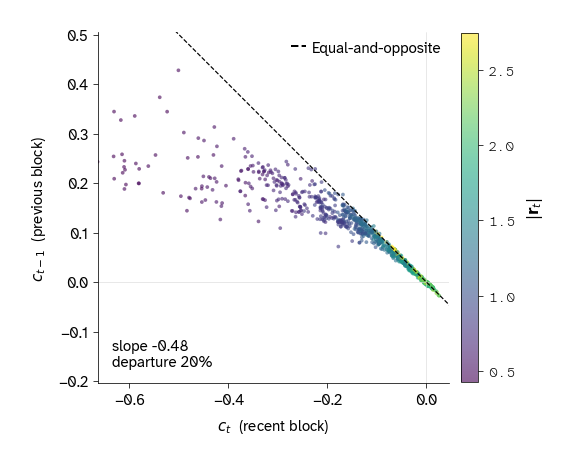

In [17]:
#| label: fig-residual-structure
#| fig-cap: "The two deviation-from-inertia operators of the noiseless short-context model, $\\mathrm{d}J_t = J_t - 2I$ and $\\mathrm{d}J_{t-1} = J_{t-1} + I$, coloured throughout by $|\\mathbf{r}_t|$."
#| fig-subcap:
#|   - "Every matrix entry of the previous block against the negative of the corresponding recent-block entry."
#|   - "The rotation score ${a^2}/(a^2 + g_1^2 + g_2^2)$ of each block."
#|   - "The rotation generator $a$, previous block against recent."
#|   - "The isotropic coefficient $c$, previous block against recent."
#| fig-alt:
#|   - "Entry-wise scatter of one operator against the negative of the other, following the dashed diagonal closely with a little spread."
#|   - "Two overlapping histograms of the rotation score, both concentrated against the right-hand edge of the axis."
#|   - "Previous against recent rotation generator, forming a tight anti-diagonal band."
#|   - "Previous against recent isotropic coefficient, a looser anti-diagonal with noticeably more spread."
#| layout-ncol: 2
#| code-fold: true
from analysis.elm import plot_residual_structure
from IPython.display import display

w_match = NT.sample_orbit_windows(BLOCK_SIZE, N_WINDOWS, seed=SEED, offset=OFFSET)
assert len(w_match) == len(all_blocks), f"{len(w_match)} vs {len(all_blocks)}"

PANEL = apc.mpl.FIGURE_SIZES_IN_INCHES['half_square']
figs  = [plt.subplots(figsize=PANEL) for _ in range(4)]
st    = plot_residual_structure([a for _, a in figs], all_blocks, w_match)
for f, a in figs:
    style_panel(a, colorbar_exists=bool(a.collections))
    display(f)
plt.close('all')


@fig-residual-structure characterizes the two operators. An entry-wise comparison across pairs of $\mathrm{d}J_t, \mathrm{d}J_{t-1}$ shows a strong negational structure, with a deviation toward small radii. 

Panels (b), (c) and (d) describe the form of each operator. Both are scaled rotations: the rotation score exceeds $0.97$ in every window, against roughly $0.25$ for an unstructured $2\times2$ matrix, so shear is negligible and each block reduces to an isotropic scale $c$ composed with a rotation generator $a$. Those two coefficients do not behave alike across the pair. The rotation generator is equal-and-opposite to within about $5\%$ per window (fitted slope $-1.10$), whereas the isotropic coefficient is only about half so (slope $-0.48$, $20\%$), mostly due to a departure from anti-symmetry at small radii.

:::


## Why the mechanism matters: rolling out the two models

A correct one-step force is only useful if it integrates into a correct orbit over a longer time horizon. To see the practical consequence of the computation strategies we identified in the two short-context models, we seed each model with two positions of a held-out orbit and let it predict autoregressively for 40 steps, feeding each prediction back as the next input. We plot the predicted orbits alongside an ideal Verlet integrator and the ground truth orbit.


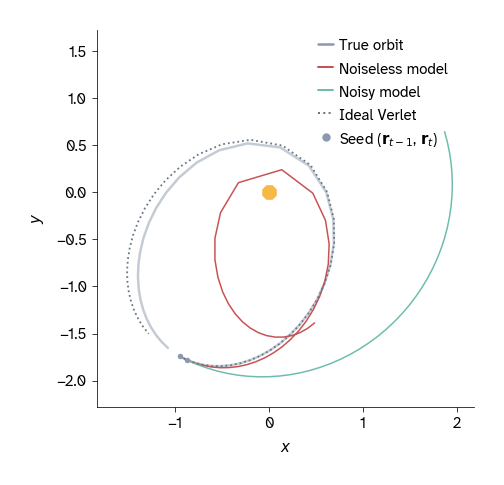

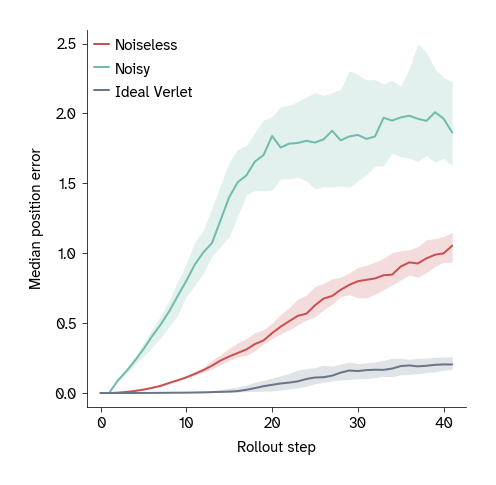

In [18]:
#| label: fig-rollout
#| fig-cap: "Autoregressive rollout on eccentric orbits (0.5 < $e$ < 0.7), seeded from two consecutive positions and rolled forward 40 steps with each prediction fed back as the next input."
#| fig-subcap:
#|   - "One example orbit seeded at aphelion, showing the true ellipse, an ideal Verlet integrator, and the two short-context models."
#|   - "Median position error against rollout step over 200 randomly drawn eccentric orbits seeded at random phase, with a 95% bootstrap confidence interval of the median."
#| fig-alt:
#|   - "Orbit traces for a sample orbit. The true ellipse and the ideal integrator nearly coincide; the noiseless model follows them at first and then drifts outward; the noisy model closes into a near-circle that departs from the ellipse immediately."
#|   - "Median position error against rollout step. The ideal integrator stays low and flat, the noiseless model climbs steadily, and the noisy model climbs fastest before levelling onto a high plateau."
#| layout-ncol: 2
#| code-fold: true
from analysis.elm import rollout, rollout_verlet
from analysis.data import load_orbital_params

N            = 40
N_ORBITS     = 200
EXAMPLE_SEED = 0     # re-roll the single example orbit in the left panel

with contextlib.redirect_stdout(io.StringIO()):
    _tr = np.asarray(load_trajectories(DATA_DIR, num_trajectories_needed=OFFSET + 2000))
    _op = load_orbital_params(DATA_DIR, num_trajectories_needed=OFFSET + 2000)
_e = np.array([p['e'] for p in _op])

# all eccentric orbits in the loaded (test-split) pool, then an UNBIASED random sample
ecc_all = [i for i in range(OFFSET, OFFSET + 2000) if 0.5 < _e[i] < 0.7]
rng     = np.random.default_rng(SEED)
sample  = rng.choice(ecc_all, size=min(N_ORBITS, len(ecc_all)), replace=False)
# Seed each rollout from a RANDOM phase along its orbit. Every trajectory is
# generated starting at perihelion, so seeding from tr[:2] would phase-lock all
# orbits at minimum radius and manufacture a spurious oscillation in the median.
offsets = rng.integers(0, 100 - (N + 2) + 1, size=len(sample))

errs = {'Noiseless': [], 'Ideal Verlet': [], 'Noisy': []}
for i, k in zip(sample, offsets):
    tr = _tr[i]; s = tr[k:k+2]; truth = tr[k:k+N+2]
    errs['Noiseless'].append(np.linalg.norm(rollout(model_noiseless, s, N)   - truth, axis=1))
    errs['Ideal Verlet'].append(np.linalg.norm(rollout_verlet(s, N, dt=DT) - truth, axis=1))
    errs['Noisy'].append(np.linalg.norm(rollout(model_bs2, s, N)             - truth, axis=1))
errs = {k: np.array(v) for k, v in errs.items()}
step = np.arange(N + 2)

# bootstrap 95% CI of the median error at each step
def median_ci(m, n_boot=2000, seed=0):
    r = np.random.default_rng(seed)
    n = m.shape[0]
    med = np.median(m, axis=0)
    idx = r.integers(0, n, size=(n_boot, n))          # resample orbits with replacement
    boot = np.median(m[idx], axis=1)                  # (n_boot, n_steps)
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    return med, lo, hi

# Example orbit: an independent random draw with its own RNG, so re-rolling the
# example (change EXAMPLE_SEED) leaves the error-curve sample untouched.
ex_rng = np.random.default_rng(EXAMPLE_SEED)
ei = int(ex_rng.choice(ecc_all))
true = _tr[ei]
# Start the example at APHELION -- the outermost point, found as the largest radius
# within the allowed start range. Like perihelion it has dr/dt = 0, so the rollout
# leaves the orbit smoothly and what stays visible is the heuristic's angular error
# rather than its radial one. Unlike perihelion it is also the *easiest* phase for a
# fixed-step integrator (slow motion, weak force): seeding at perihelion instead makes
# dt = 20/99 far too coarse for the 1/r^2 force there, and the ideal-Verlet reference
# itself takes a permanent energy hit, ending up less accurate than either model.
# The error curves on the right keep their random phases -- phase-locking those would
# manufacture a spurious oscillation in the median.
ek = int(np.argmax(np.linalg.norm(true[:100 - (N + 2) + 1], axis=1)))
s = true[ek:ek+2]; seg = true[ek:ek+N+2]
rn, rv, rx = rollout(model_noiseless, s, N), rollout_verlet(s, N, dt=DT), rollout(model_bs2, s, N)

PANEL = apc.mpl.FIGURE_SIZES_IN_INCHES['half_square']
C_NOISELESS = C_MODEL_NOISELESS
C_VERLET = C_IDEAL
C_NOISY = C_MODEL_NOISY

fig, ax = plt.subplots(figsize=PANEL)
ax.plot(seg[:, 0], seg[:, 1], '-', color=C_TRUE, lw=2.5, alpha=0.5, label='true orbit')
ax.plot(rn[:, 0], rn[:, 1], '-', color=C_NOISELESS, lw=1.5, label='noiseless model')
ax.plot(rx[:, 0], rx[:, 1], '-', color=C_NOISY,      lw=1.5, label='noisy model')
ax.plot(rv[:, 0], rv[:, 1], ':', color=C_VERLET,    lw=1.8, label='Ideal Verlet')
ax.scatter(0, 0, marker='8', s=250, color=str(apc.canary), edgecolor=str(apc.crow), zorder=5)
ax.scatter(s[:, 0], s[:, 1], color=C_TRUE, s=30, zorder=5,
           label=r'seed ($\mathbf{r}_{t-1}$, $\mathbf{r}_t$)')
ax.set_aspect('equal')
# Square the data box so this equal-aspect panel ends up the same shape as the
# error curve beside it (otherwise the orbit's 1.3:1 extent sets the output
# aspect and the two panels mismatch). The slack is anchored above the data,
# which is also where the legend then sits clear of every trajectory.
_pts = np.vstack([seg, rn, rx, rv, [[0.0, 0.0]]])
_span = 1.16 * max(np.ptp(_pts[:, 0]), np.ptp(_pts[:, 1]))
_x0 = _pts[:, 0].min() - 0.08 * _span
_y0 = _pts[:, 1].min() - 0.08 * _span
ax.set_xlim(_x0, _x0 + _span); ax.set_ylim(_y0, _y0 + _span)
ax.set_xlabel(r'$x$'); ax.set_ylabel(r'$y$')
ax.legend(frameon=False, loc='upper right', bbox_to_anchor=(0.95, 1.0))

style_panel(ax)
plt.show()

fig, ax = plt.subplots(figsize=PANEL)
for name, c, lab in [('Noiseless',    C_NOISELESS, 'noiseless'),
                     ('Noisy',        C_NOISY,     'noisy'),
                     ('Ideal Verlet', C_VERLET,    'Ideal Verlet')]:
    med, lo, hi = median_ci(errs[name], seed=SEED)
    ax.plot(step, med, color=c, lw=2, label=lab)
    ax.fill_between(step, lo, hi, color=c, alpha=0.2)
ax.set_xlabel('rollout step'); ax.set_ylabel('median position error')
ax.legend(frameon=False)
style_panel(ax)
plt.show()


@fig-rollout-1 shows that the noiseless model tracks the true orbital ellipse well early in the rollout and then accumulates error as it proceeds, demonstrating that while it has learned an approximate one-step force, small per-step errors compound, and it never matches the accuracy of an ideal Verlet scheme, which stays closest to the truth throughout. The noisy model's local circular-orbit heuristic becomes obvious with just a few rollout steps, as it quite literally turns the ellipse into a circle, missing the true orbit from the very first steps. Its error is large but bounded, saturating as it settles onto a stable, wrong, circular path rather than diverging. This behavior is further evident when plotting median error across many orbits (@fig-rollout-2). The Verlet integrator keeps error low across many rollout steps, the noiseless model tracks Verlet for a handful of steps before accumulating error, while the noisy model rapidly gains error before plateauing in a stable, high error regime.


## Why the probe recovers force in both models
Linear probing reports the Newtonian force at $R^2 \approx 1.0$ in both short-context models, yet the two compute entirely different things: one integrates a force, the other turns the planet on a circle. A probe that cannot separate those two is reporting something other than the computation. What is it reading?

To probe this, we investigated where the linear probes are drawing information from the models, and how this compares to the overall variance in their internal activation space. We focus on the final LayerNorm, the last representation before the output head. Taking its principal components over held-out windows we ask two things of each component in turn: how much of the activation variance does it carry, and how much does it add to a linear probe's ability to read $|\mathbf F|$? Components are ordered by variance, so the question is what is available in the directions the representation actually moves along.


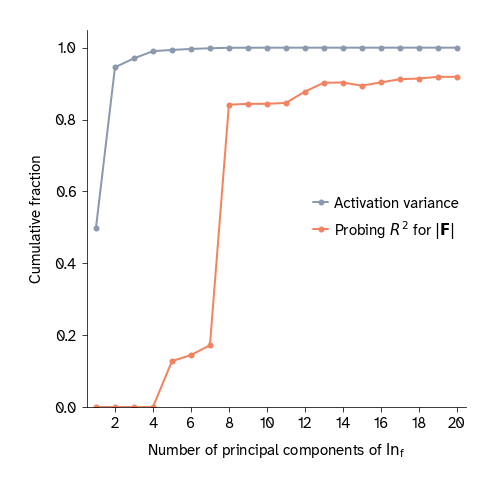

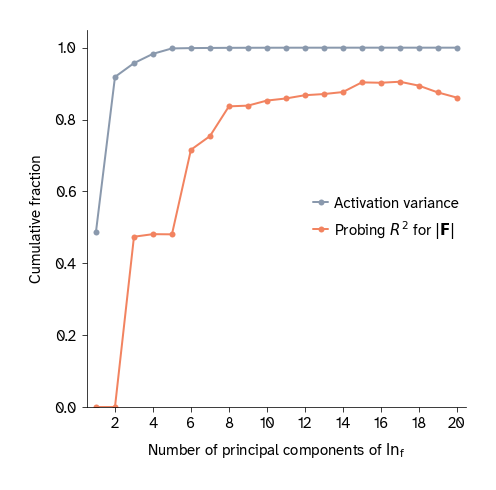

In [19]:
#| label: fig-scree-probe
#| fig-cap: "Cumulative activation variance and cumulative force decodability, against the number of leading principal components of the final layernorm ($\\mathrm{ln_f}$). Components are ordered by activation variance."
#| fig-subcap:
#|   - "Noisy short-context model."
#|   - "Noiseless short-context model."
#| fig-alt:
#|   - "Two curves against the number of components. Cumulative variance rises almost immediately to its ceiling, while probe performance stays near the bottom before climbing in a late step."
#|   - "The same two curves for the noiseless model, with the probe curve beginning its climb earlier."
#| layout-ncol: 2
#| code-fold: true
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

N_SUB = 4000
W_sub = NT.sample_orbit_windows(BLOCK_SIZE, N_SUB, seed=SEED, offset=OFFSET)
r_prev_s, r_t_s = W_sub[:, -2, :], W_sub[:, -1, :]
rad_s  = np.linalg.norm(r_t_s, axis=1)
grav_s = -r_t_s / rad_s[:, None] ** 3                 # true Newtonian acceleration, GM = 1
F_s    = 1.0 / rad_s ** 2
i_tr, i_te = train_test_split(np.arange(N_SUB), test_size=0.5, random_state=0)


def subspace_sweep(mdl):
    """Per k, everything this section needs from the top-k principal components of ln_f.

    The output head is linear and bias-free, so the prediction splits exactly and
    additively: y = W_head @ bulk_k + W_head @ tail_k (asserted below). Components
    are ordered by activation variance, never by usefulness for |F|.

    Returns  var   per-component share of activation variance
             r2    held-out probing R^2 for |F| from the top-k
             rho   fraction of the gravitational kick the bulk-only output reproduces,
                   1 - |a_bulk - g| / |g|, per window then median
    """
    rec = {}
    hk = mdl.transformer.ln_f.register_forward_hook(
        lambda m, i, o: rec.__setitem__('L', o.detach()[:, -1, :].double().clone()))
    try:
        with torch.no_grad():
            pred = mdl(torch.tensor(W_sub).to(next(mdl.parameters()).dtype))[0][:, -1, :]
    finally:
        hk.remove()
    L  = rec['L'].numpy()
    Wh = mdl.output_head.weight.detach().double().numpy()
    assert np.abs(L @ Wh.T - pred.double().numpy()).max() < 1e-10
    mu = L[i_tr].mean(0)
    _, S, Vt = np.linalg.svd(L[i_tr] - mu, full_matrices=False)
    P   = (L - mu) @ Vt.T
    var = S ** 2 / (S ** 2).sum()
    ng  = np.linalg.norm(grav_s, axis=1)
    r2, rho = [], []
    for k in range(1, L.shape[1] + 1):
        r2.append(r2_score(F_s[i_te],
                           LinearRegression().fit(P[i_tr][:, :k], F_s[i_tr])
                                             .predict(P[i_te][:, :k])))
        y_bulk = mu @ Wh.T + P[:, :k] @ (Vt[:k] @ Wh.T)
        a_bulk = (y_bulk - 2 * r_t_s + r_prev_s) / DT ** 2
        rho.append(np.median((1 - np.linalg.norm(a_bulk - grav_s, axis=1) / ng)[i_te]))
    return dict(var=var, cum=np.cumsum(var), r2=np.array(r2), rho=np.array(rho))


SUB = {r'noisy  ($\sigma=0.1$)':     subspace_sweep(model_bs2),
       r'noiseless  ($\sigma=0.0$)': subspace_sweep(model_noiseless)}

PANEL = apc.mpl.FIGURE_SIZES_IN_INCHES['half_square']

# The sweep runs over all 32 components, but the interesting structure is in the
# first K_MAX. Truncate the series rather than letting the axis clip it: clipping
# leaves the line running past its last marker into the spine.
K_MAX = 20
for d in SUB.values():
    ks = np.arange(1, len(d['var']) + 1)
    keep = ks <= K_MAX
    fig, ax = plt.subplots(figsize=PANEL)
    ax.plot(ks[keep], np.asarray(d['cum'])[keep], color=ARC_VIBE, marker='o',
            label='Activation variance')
    ax.plot(ks[keep], np.clip(np.asarray(d['r2'])[keep], 0, None), color=ARC_CORAL, marker='o',
            label=r'Probing $R^2$ for $|\mathbf{F}|$')
    ax.set_xlabel(r'number of principal components of $\mathrm{ln_f}$')
    ax.set_ylabel('cumulative fraction')
    ax.set_xlim(0.5, K_MAX + 0.5); ax.set_ylim(0, 1.05)
    ax.set_xticks(np.arange(2, K_MAX + 1, 2))
    ax.legend(loc='center right', frameon=False)
    style_panel(ax)
    plt.show()


@fig-scree-probe shows that the activations in the final LayerNorm are low rank in both models with the first two principal components carrying over 90% of the variance. Conversely, the linear probe force readouts are decoded from the long, low-variance dimension tail. In the noisy model the majority of the readout arrives with component 8 while in the noiseless model the single largest gain occurs earlier at component 3. That the probe uses low-variance dimensions is not necessarily an issue in and of itself. The gravitational kick is usually much smaller in scale than inertia; therefore, it being encoded in low-variance dimensions does not strictly mean that it is not used in the final prediction. We can test this question more explicitly by ablating dimensions from the final LayerNorm output and observing their effect on the predicted shift away from inertia (which we previously established as capturing gravity in the noiseless model).  

Split the representation into the bulk $k$ leading components (carrying the majority of the variance), and the tail, carrying everything else. Because the output head is linear and bias-free, the prediction splits with it, exactly and additively:

$$\hat{\mathbf r}_{t+1} \;=\; \underbrace{W_{\text{head}}\,\ell_{\le k}}_{y_{\text{bulk}}} \;+\; \underbrace{W_{\text{head}}\,\ell_{>k}}_{y_{\text{tail}}}$$

so we can ask what the model still computes from the bulk alone. Taking the effective acceleration of the bulk-only prediction exactly as in @fig-newton-behavioral, we score it against true gravity as the fraction of the kick reproduced,

$$\rho \;=\; 1 - \frac{|\,\mathbf a_{\text{bulk}} - \mathbf g\,|}{|\,\mathbf g\,|}$$

which is 1 when the kick exactly matches gravity in direction and magnitude, 0 when the bulk output is no better than having no kick at all, and negative when it is worse than omitting gravity altogether.

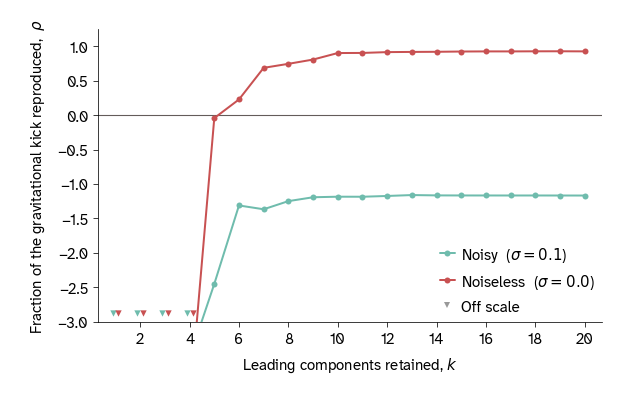

In [20]:
#| label: fig-bulk-tail
#| fig-cap: "Median fraction of the gravitational kick reproduced by the bulk-only prediction ($\\rho$), against the number of leading principal components ($k$) retained. As $\\rho$ approaches 1 the gravitational kick is reproduced exactly (both direction and magnitude), while negative values indicate a deviation from inertia that is worse than omitting gravity altogether. Downward triangles at the bottom edge mark values of $k$ whose $\\rho$ falls below the axis limit and is off scale."
#| fig-alt: "Two curves of reproduced kick fraction against components retained. One rises steeply and flattens near the top of the axis; the other rises only to a negative plateau and stays there. Triangles along the bottom edge mark off-scale values at the smallest component counts."
#| code-fold: true
YLO, YHI = -3.0, 1.25

fig, ax = plt.subplots(figsize=apc.mpl.FIGURE_SIZES_IN_INCHES['float'])
ax.axhline(0, color=ARC_DIAG, lw=1.1, zorder=1)

offsets = (-0.12, 0.12)    # nudge the two models' triangles apart so they don't overlap
for (name, d), colour, dx in zip(SUB.items(), (C_MODEL_NOISY, C_MODEL_NOISELESS), offsets):
    ks  = np.arange(1, len(d['rho']) + 1)
    rho = np.asarray(d['rho'])
    keep = ks <= K_MAX          # same window as @fig-scree-probe; see note there
    ks, rho = ks[keep], rho[keep]

    # true values: matplotlib clips the line at the axis edge, so segments
    # entering from below stay visible
    ax.plot(ks, rho, 'o-', color=colour, label=name, zorder=3)

    # mark every off-scale point with a downward triangle just inside the bottom edge
    off = rho < YLO
    if off.any():
        ax.scatter(ks[off] + dx, np.full(off.sum(), YLO + 0.12), marker='v', s=40,
                   color=colour, edgecolor='k', linewidths=0, zorder=5, clip_on=False)

# one legend entry explaining the triangles
ax.plot([], [], 'v', color='0.6', mec='none', ls='', label='off scale')

ax.set_xlim(0.3, K_MAX + 0.7); ax.set_ylim(YLO, YHI); ax.set_xticks(np.arange(2, K_MAX + 1, 2))
ax.set_xlabel('leading components retained, $k$')
ax.set_ylabel(r'fraction of the gravitational kick reproduced,  $\rho$')

# drop the unlabelled stray handle that appears above the first entry
h, l = ax.get_legend_handles_labels()
keep = [i for i, lab in enumerate(l) if lab.strip() and not lab.startswith('_')]
ax.legend([h[i] for i in keep], [l[i] for i in keep], frameon=False)

style_panel(ax)
plt.show()

@fig-bulk-tail shows that the noisy model never approaches one at any $k$ and therefore never captures the expected gravitational kick. None of the tested principal component subspaces of its representation yields an output that reproduces gravity, because its output is primarily rotation. In the noiseless model the gravitational kick starts to emerge at $k=5$, while the linear probe appears to capture Newtonian force components much earlier, returning an $R^2$ of ~0.5 by just $k=4$.

So the two models differ not in *where* their fine structure sits but in what that structure does. Both decode force from the tail but in one the tail also supplies the gravitational kick. However, even in the noiseless model, linear probes suggest that force should emerge in earlier principal components than what we observe in practice, highlighting the disconnect between decodability and utilization. 

## Conclusions 

By combining ELM with a battery of behavioral tests, we show that the short-context model trained by @liu2026kepler has not learned a Newtonian world model, despite seemingly encoding Newtonian force components. Rather, it runs a radius-based heuristic, rotating the most recent positional input by roughly the angle that a circular orbit of that radius would sweep. The key to forcing a more Newtonian world model in this system rests on removing input noise during training. Liu et al. benchmarked noise addition for a much longer context length (50 input positions). In this setting, with a long tail of seen positions, noise is indeed beneficial for stabilizing model rollout as established by the authors. However, our own rollout experiments with short-context models have shown that noise is actively harmful when few input positions are available for efficient input denoising. Critically, input noise is highly detrimental to the desired “true” world model in this system as it swamps any signal of the gravitational kick. It is therefore unsurprising that we observed a strong shift in the internal computation strategy of the short-context model when we removed noise during training, bringing the final model much closer to learning a true Newtonian representation of the system.

Inspecting the internal computation of a network, or running behavioral tests alone, is not enough to establish the learned world model. There exist an infinite number of linear combinations of input positions that can be used to calculate the next planetary position in an orbit. Our solution to this problem is to predefine the world model based on an expected analytical solution, which is directly derived from Newton’s laws: the Verlet integrator. This reference requires inertia to be captured in the two planetary positions the model receives as input, providing a constraint on the content Jacobians, allowing us to quantify world model state. However, while our results undoubtedly suggest that the noiseless short-context model uses the content Jacobians to capture inertia, the additional input term from the positional embedding vector means we do not recover a unique global computation strategy. Rather, the gravitational kick seems to be encoded in a complex way in both the content and positional-embedding Jacobians, with cancellation between them. Because of the degrees of freedom provided by these two terms, different orbits, differing parts of the same orbit, and certainly different seeds of this model will differ both in how gravity is computed among these terms, and also in how close the content Jacobians get to the inertial point. The more unnecessary cancellations there are between the two term types, the further the computation will drift from the inertial point, even if the model ultimately approximates Verlet integration. Is the model still Newtonian if its computation drifts far from the inertial point for a given input window because of large cancellable contributions from multiple input terms? We posit that viewing learned world models through the lens of a continuous distribution is likely more useful than assigning strict states. This framework aligns with our analyses, which, in aggregate, support the conclusion that the noiseless model is a good approximator of Verlet integration, although there are individual orbit windows where the internal computation appears to deviate significantly from that pattern.  

Our work, and the preceding results of both @liu2026kepler and @vafa2025foundation in this toy system, also raise questions about the fragility of leveraging learned world models when the ground truth is unknown, arguably one of the more enticing applications of world model inference. Overall, our work has shown that, at least for the task of planetary orbit prediction, a model must be strongly architecturally constrained to get it anywhere close to the “true” Newtonian world model. This constraint comes at a high cost; for example, Liu et al. showed that long-context models have by far the best performance when predicting planetary positions over many rollout steps, yet those models will undoubtedly be the furthest from performing Verlet integration. This is troubling since models are evaluated primarily on their predictive performance, which in this system would lead us to infer unnecessarily complex and misleading world models (see also @vafa2025foundation for this point). Training recipes tuned on predictive metrics may therefore be unintentionally selecting among world models, and hyperparameters like noise scale and rollout horizon should be treated as interpretability-relevant choices.

Finally, our use of a reference solution as a baseline is convenient, but it is not the usual approach in the world model literature and comes with clear limits. It requires an analytic ground-truth computation to compare against and a map simple enough to read, two constraints that are often not available: in natural language, there is no Verlet-like baseline, and even here, the long-context model was too complex for us to interpret its ELM readouts, which is why we restricted the mechanistic analysis to the two-token model. We have also varied only two context lengths, one architecture, and a single 2D orbital domain, so we take our results as a worked demonstration rather than a general law.

